# XFEL $F_o-F_c$ map of an omit model with optional refinement

This notebook calculates the weighted difference map $mF_o-DF_c$ for an **omit / reference model** against one set of **observed amplitudes**, extracts a fragment around a site of interest, and renders a publication-style figure in PyMOL.

The default example is photosystem II, Fig. 2B of the Wang, Armstrong & Batista comparison (PNAS, 2021), using the Ibrahim *et al.* (Science, 2020) 2F dataset:

| Role | What it supplies |
| --- | --- |
| Omit model | single-conformation coordinates of an "omit" model |
| Observed amplitudes | 2F, 200 ms structure factors |

REFMAC is run once, with the omit coordinates and the light amplitudes, for the number of cycles set in the configuration cell. Chosen distances in the site residue are passed to that job with a large standard deviation, so those atoms can move. Chosen angles are passed as external angles. Set `USE_LIBCHECK` to build a `libcheck` monomer library for the distances instead. The job writes the refined coordinates, $F_o$ (`FP`), $F_c$ (`FC` / `FC_ALL`), and the weighted difference `DELFWT` / `PHDELWT` in one MTZ. The map is the Fourier transform of `DELFWT` / `PHDELWT`. No second dataset is scaled in, so `scaleit` is not used. `cad` only copies the `FREE` flag from the intensity MTZ onto the amplitudes.

## What the pipeline does

1. **Check** that the omit coordinates, the observed structure-factor mmCIF, CCP4, Coot, and PyMOL are available.
2. **Convert** the observed reflection mmCIF $\rightarrow$ MTZ (`cif2mtz`), intensities to amplitudes (`ctruncate`), then copy `FREE` onto those amplitudes (`cad`).
3. **Refine** the omit model against those amplitudes for `REFMAC_NCYC` cycles of `refmac5`. By default the chosen site distances are external restraints with a large standard deviation, and the chosen site angles are external angles. `USE_LIBCHECK = True` widens those distances in a `libcheck` library instead; the angles stay external. The same job writes $F_o$ (`FP`), $F_c$ (`FC` / `FC_ALL`), and `DELFWT` / `PHDELWT`.
4. **Fourier-transform** `DELFWT` / `PHDELWT` (`fft`) and **extend** the map around the refined model (`extends`).
5. **Export** a radius-limited map fragment around the chosen site with headless Coot.
6. **Load the refined structure with that difference map** in PyMOL, **contour** the fragment at user-defined $\pm n\sigma$, **save a PNG**, and **display it in this notebook**.


## Background

The map in this notebook is the REFMAC weighted difference

$$
\Delta\rho(\mathbf{r}) \;\propto\; \sum_{hkl} (m|F_o|-D|F_c|)\, e^{i\varphi_c}\, e^{-2\pi i \mathbf{h}\cdot\mathbf{r}},
$$

with $F_o$ the observed light amplitudes and $F_c$, $\varphi_c$ calculated from the omit model. REFMAC stores that coefficient as `DELFWT` / `PHDELWT`. The same MTZ also contains the observed amplitude `FP` (`SIGFP`) and the calculated amplitude `FC` / `FC_ALL` (`PHIC` / `PHIC_ALL`). Because $F_o$ and $F_c$ were scaled together inside that one job, a second program does not have to put them on a common scale.

**How to read the map**

- **Positive** density (green $\rightarrow$ cyan $\rightarrow$ blue at increasing $\sigma$): electrons in the observations that the omit model does not account for.
- **Negative** density (red $\rightarrow$ salmon $\rightarrow$ magenta): electrons the omit model places where the observations are weaker.
- A feature present in the data and absent from the model (for example an oxygen left out of a single-conformation cluster) is a **positive** peak.

Difference maps from XFEL data are noisy and the activated-state occupancy is often only 10–30 %. Contouring at $3\sigma$ shows weaker (and noisier) features; $4$–$5\sigma$ keeps only the strongest peaks. There is no single “correct” level — report the level you used and inspect a range.

**Files you need**

| File | Typical name | Where to get it |
| --- | --- | --- |
| Omit-model coordinates | `{omit}.pdb` | the single-conformation (or otherwise omitted) model |
| Observed structure factors | `{light}-sf.cif` | [RCSB](https://www.rcsb.org) structure factors for the dataset the model is compared with |
| Light coordinates (optional, for display) | `{light}.pdb` | RCSB coordinates; the figure is drawn on the omit model |

The deposited structure factors are intensities (`I`, `SIGI`). `ctruncate` converts them to amplitudes (`F`, `SIGF`); REFMAC reads those amplitudes and writes `FP`. The omit model's own structure-factor file is not an input: $F_o$ always comes from the light dataset.

## Required packages

In [31]:
from __future__ import annotations

import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

try:
    from IPython.display import Image, Markdown, display
except ImportError:  # running as a plain script rather than a notebook
    def display(obj=None, **kwargs):
        print(getattr(obj, "data", obj))

    class Image:  # noqa: N801
        def __init__(self, filename=None, width=None):
            self.filename = filename

        def __repr__(self):
            return f"[image {self.filename}]"

    class Markdown:  # noqa: N801
        def __init__(self, data=""):
            self.data = data

        def __repr__(self):
            return str(self.data)

## How to choose parameters

Edit the **configuration cell** below. Everything downstream reads from that cell; you should not need to edit the CCP4/Coot/PyMOL code.

### Structures and files

- `DARK_ID` is the omit model. `LIGHT_ID` is the observed dataset. Both are short labels used in output names (`11yo`, `6w1v`, …). They do not have to be PDB codes.
- If you leave a path as `None`, it is built from the naming convention above inside `INPUT_DIR`.
- Override any path when your files are named differently (`6w1v.pdb` instead of `6w1v-pdb-bundle1.pdb`, mmCIF coordinates, …). Both `.pdb` and `.cif` coordinates are accepted by REFMAC.
- The map needs the omit coordinates and the light structure factors. The light coordinates are loaded only so the residue scan can be compared with the dataset the model was refined against. The figure itself is drawn on the REFMAC output, the refined omit model.

### Resolution (`RESOLUTION_SOURCE`, `LOWRES`, `DMIN`)

- `RESOLUTION_SOURCE = "sf"` takes `LOWRES` and `DMIN` from the observed structure-factor **MTZ** after `cif2mtz`. `mtzdump` reports the resolution range of the reflections. The mmCIF often has no `pdbx_d_res_low` / `pdbx_d_res_high`.
- `RESOLUTION_SOURCE = "explicit"` ignores that range and uses the `LOWRES` and `DMIN` numbers in the configuration cell.
- `DMIN` should be **no finer than the high-resolution limit of the observed data**.

### Refinement

- `REFMAC_NCYC` is the number of `refmac5` cycles applied to the omit model. `0` calculates the map without moving atoms. The default `5` refines coordinates and B factors against the observed amplitudes.
- `SITE_DISTANCE_RESTRAINTS` lists atom pairs in `SITE_RESI`. Each entry is `(atom_1, atom_2)`, or `(atom_1, atom_2, distance_Å)`, or `(atom_1, atom_2, distance_Å, sigma_Å)`. Leave the distance out (or set it to `None`) to keep the distance in the starting model. The default pairs are Mn1–O5, Mn3–O5, and Mn4–O5. An empty list adds no distance restraints.
- `SITE_DISTANCE_SIGMA` (default 0.50 Å) is the standard deviation used when an entry does not set its own. A normal dictionary bond is about 0.02 Å, so 0.50 Å is loose and those atoms can move.
- `SITE_ANGLE_RESTRAINTS` lists angles in `SITE_RESI`. Each entry is `(atom_1, vertex, atom_3)`, or `(atom_1, vertex, atom_3, angle_deg)`, or `(atom_1, vertex, atom_3, angle_deg, sigma_deg)`. The angle is at the middle atom. Leave the angle out (or set it to `None`) to keep the angle in the starting model. These are passed to `refmac5` as external angles for the residues in `SITE_COPIES`. An empty list adds no angle restraints.
- `SITE_ANGLE_SIGMA` is the standard deviation in degrees used when an entry does not set its own. `refmac5` reads that `sigma` in degrees, so the number is written unchanged and is not converted to radians.
- `USE_LIBCHECK` chooses how the distance restraints are applied. `False` (default) passes them to `refmac5` as external distances. REFMAC then uses that restraint instead of the dictionary bond for the same atom pair, and only in the residues listed in `SITE_COPIES`. `True` runs `libcheck` and widens the distances in the monomer library, which applies to every copy of that residue type. Angle restraints stay external either way. An empty `SITE_DISTANCE_RESTRAINTS` list leaves the library distances unchanged.
- `LIB_MONOMERS` selects the residue names passed through `libcheck` when `USE_LIBCHECK` is `True`. `None` uses the residue type of `SITE_RESI` and every other non-water hetero residue in the omit model. The file has the same layout as `data/9z35/9z35_OEIOEOCLAHECUNL_lib.cif`. If the coordinates of a residue are not connected well enough for `libcheck` (this happens for LMG), that residue is copied from the CCP4 monomer library instead.

### Site of interest

- `SITE_CHAIN` and `SITE_RESI` centre the Coot export and the PyMOL view.
- For **6w1v**, chain `A` residue **416** is ligand `OEY`, the major (75 %) 2F OEC conformation that includes O6. Residue **415** is `OEX`, the minor conformation without O6. The DARK structure `6w1o` stores the unique OEC as `OEX` at residue **414** — residue numbers are **not** interchangeable across PDB entries. Always confirm with the residue-scan cell.
- `SITE_COPIES` may list several `(chain, resi)` pairs if you want one map fragment per monomer.
- `EXTRA_RESIDUES` are neighbouring amino acids drawn as sticks (D1-Glu189 in the default example).
- `SITE_LABEL` is only used in file names (`OEC`, `heme`, `chromophore`, …).

### $\pm\sigma$ contour

- `SIGMA_LEVELS = [3, 4, 5]` draws three nested meshes, matching the usual PSII figure.
- Use a single value, e.g. `[4.0]`, for a cleaner image.
- `SIGMA_POSITIVE` / `SIGMA_NEGATIVE` can be set independently if you want, for example, $+5\sigma$ / $-3\sigma$.
- `surface_representation = "mesh"` (default) draws a wireframe (`isomesh`). `"solid"` draws a transparent surface (`isosurface`).
- `CONTOUR_MODE = "sigma"` (default) lets PyMOL normalise the CCP4 map to RMS = 1, so a level of `3` **is** $3\sigma$. `"absolute"` turns that normalisation off and treats the numbers as raw map units.

### Map fragment

- `EXPORT_RADIUS_A` (default 10 Å) is the Coot clip radius around the site centroid.
- `CARVE_A` (default 3 Å) hides mesh that is farther than this from any displayed atom, so the cage does not swallow the model.
- `MAP_BORDER_A` (default 5 Å) is the `extends` padding around the omit-model coordinates.

### Re-runs

- `RECOMPUTE_MAP = False` reuses an existing extended CCP4 map (the slow REFMAC/FFT steps).
- `RECOMPUTE_FRAGMENT = False` reuses an existing Coot `.map` clip.
- PyMOL is always re-run so that contour, colour, and camera changes are cheap to iterate.
- `INSPECT_IN_PYMOL = True` opens that scene in the PyMOL GUI after the PNG is shown. Quit PyMOL after moving the camera; the notebook stores the view and redraws the figure.


In [32]:
# ---------------------------------------------------------------------------
# Configuration — edit this cell for a new omit model and dataset
# ---------------------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd().resolve()

# single-conformation model (with O6 absent)
DARK_ID  = "6w1v_omitO6_single_confB"

# structure corresponding to observed amplitudes
LIGHT_ID = "6w1v"

print(f"'Omit' model: {DARK_ID}")
print(f"Reference 2F model:   {LIGHT_ID}")

INPUT_DIR = NOTEBOOK_DIR / "data"     # where the downloaded PDB / sf files live
OUTPUT_DIR = NOTEBOOK_DIR / "work-2b-6w1v-confB-norefinement"
print(f"OUTPUT DIRECTORY: {OUTPUT_DIR}")

# Leave a path at None to use the standard RCSB-style name inside INPUT_DIR.
DARK_PDB = None           # omit-model coordinates
LIGHT_PDB = None          # light coordinates, used for the residue scan and display comparison
LIGHT_SF = None           # observed structure factors for LIGHT_ID

CCP4_ROOT = Path("/Applications/ccp4-9")

# Resolution cutoffs for fft, in Å.
# "sf" reads the range from the observed structure-factor MTZ after cif2mtz (mtzdump).
# "explicit" uses the LOWRES and DMIN numbers below and ignores the MTZ range.
RESOLUTION_SOURCE = "sf"  # "sf" or "explicit"
LOWRES = 30.0              # explicit low-resolution cutoff (Å); ignored when SOURCE is "sf"
DMIN = 1.89                # explicit high-resolution cutoff (Å); ignored when SOURCE is "sf"

if RESOLUTION_SOURCE == "explicit":
    LOWRES = float(LOWRES)
    DMIN = float(DMIN)
    if not (LOWRES > DMIN > 0):
        raise ValueError(f"Expected LOWRES > DMIN > 0, got {LOWRES} and {DMIN}")
    print(f"Explicit resolution: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
elif RESOLUTION_SOURCE == "sf":
    print("Resolution cutoffs will be read from the structure-factor MTZ in the map cell.")
else:
    raise ValueError(
        "RESOLUTION_SOURCE must be 'sf' or 'explicit', "
        f"got {RESOLUTION_SOURCE!r}"
    )

MAP_BORDER_A = 5.0        # EXTENDS border around the omit model (Å)
print(f"Map border: {MAP_BORDER_A}")
print("Map coefficient: DELFWT / PHDELWT (mFo-DFc) from REFMAC of the omit model against the light amplitudes")

# Number of refmac5 cycles applied to the DARK model.
# 0 calculates the map without moving atoms.
REFMAC_NCYC = 0

# Distance restraints inside SITE_RESI. Each item is
# (atom_1, atom_2), (atom_1, atom_2, distance_A), or
# (atom_1, atom_2, distance_A, sigma_A).
# A missing distance (or None) keeps the distance in the starting model.
# A missing sigma uses SITE_DISTANCE_SIGMA. That sigma is large next to a
# normal dictionary bond (~0.02 A), so these atoms can move.
# An empty list adds no distance restraints.
SITE_DISTANCE_RESTRAINTS = [
    ("MN1", "O5"),
    ("MN3", "O5"),
    ("MN4", "O5"),
    ("CA1", "O5"),
]
print(f"Site-distance restraints: {SITE_DISTANCE_RESTRAINTS}")
SITE_DISTANCE_SIGMA = 0.5

# Angle restraints inside SITE_RESI. Each item is
# (atom_1, vertex, atom_3), (atom_1, vertex, atom_3, angle_deg), or
# (atom_1, vertex, atom_3, angle_deg, sigma_deg).
# The angle is at the middle atom. A missing angle (or None) keeps the
# angle in the starting model. A missing sigma uses SITE_ANGLE_SIGMA.
# Both the angle and SITE_ANGLE_SIGMA are degrees. refmac5 reads them as
# degrees, so neither is converted to radians.
# An empty list adds no angle restraints. These lines are external angles
# for every residue in SITE_COPIES, whether or not USE_LIBCHECK is set.
SITE_ANGLE_RESTRAINTS = [
("MN3", "O5", "MN4"),
("MN3", "O5", "CA1"),
("MN4", "O5", "CA1"),
("O5", "CA1", "O1"),
("O2", "MN3", "O5"),
("O3", "MN3", "O5"),
("O4", "MN3", "O5"),
("O4", "MN4", "O5"),
]

print(f"Site-angle restraints: {SITE_ANGLE_RESTRAINTS}")
SITE_ANGLE_SIGMA = 25
print(f"Site-angle sigma: {SITE_ANGLE_SIGMA:g} deg")

# False: pass SITE_DISTANCE_RESTRAINTS to refmac5 as external distances.
# Each one replaces the dictionary bond for that atom pair in SITE_COPIES.
# True: build a libcheck monomer library and widen those distances there.
# The library change applies to every copy of that residue type.
# SITE_ANGLE_RESTRAINTS are external angles in either case.
# An empty distance or angle list adds no restraints of that kind.
USE_LIBCHECK = False

# Residue names written into the REFMAC library by libcheck.
# Used only when USE_LIBCHECK is True.
# None: the SITE_RESI residue type plus every other non-water hetero residue.
LIB_MONOMERS = None

print(f"REFMAC cycles: {REFMAC_NCYC}")
print(f"Loose site-distance sigma: {SITE_DISTANCE_SIGMA:g} A")
if SITE_DISTANCE_RESTRAINTS:
    print(
        "Distance restraints:",
        "libcheck library" if USE_LIBCHECK else "refmac5 external distances",
    )
else:
    print("Distance restraints: none")
if SITE_ANGLE_RESTRAINTS:
    print("Angle restraints: refmac5 external angles")
else:
    print("Angle restraints: none")

SITE_CHAIN = "A"
SITE_RESI = 416           # "dark" OEY (major 2F OEC, O6 removed)
SITE_LABEL = "OEC"
SITE_COPIES = [           # Coot exports one fragment per entry
    (SITE_CHAIN, SITE_RESI),
]
EXTRA_RESIDUES = [        # drawn as sticks in PyMOL; empty list is fine
    {"chain": "A", "resi": 189, "label": "GLU189"},
]

EXPORT_RADIUS_A = 10.0
CARVE_A = 3.0

SIGMA_LEVELS = [3.5]
SIGMA_POSITIVE = None     # None → SIGMA_LEVELS
SIGMA_NEGATIVE = None     # None → SIGMA_LEVELS
CONTOUR_MODE = "sigma"    # "sigma" or "absolute"
surface_representation = "mesh"  # "mesh" or "solid"
if surface_representation not in {"mesh", "solid"}:
    raise ValueError(
        "surface_representation must be 'mesh' or 'solid', "
        f"got {surface_representation!r}"
    )
print("Sigma levels: [" + ", ".join(f"±{level}" for level in SIGMA_LEVELS) + "]")
print(f"Surface representation: {surface_representation}")

SHOW_OEC_BONDS = True     # Mn/Ca–O bonds if those atom names exist
DRAW_DEFAULT_OEC_DISTANCES = True

# Set to None to auto-orient on the site.

PYMOL_VIEW = None

#PYMOL_VIEW = '''\
#-0.222551167, -0.711501896, -0.666503847,\
# 0.638767481,  0.410044461, -0.651020229,\
# 0.736502111, -0.570636272,  0.363232195,\
# 0.000000000,  0.000000000, -42.280372620,\
#-34.986000061, 39.219001770, 364.061004639,\
# 37.280372620, 47.280372620, -20.000000000'''

# Set True to open the rendered scene in the PyMOL GUI after the PNG is shown.
# Quit PyMOL when the camera looks right; the figure is redrawn and a PYMOL_VIEW
# matrix is printed so you can paste it above.
INSPECT_IN_PYMOL = True

PNG_WIDTH = 3200
PNG_HEIGHT = 1600
RAY_TRACE = True

RECOMPUTE_MAP = True
RECOMPUTE_FRAGMENT = True

POS_COLORS = ["forest", "cyan", "blue", "density"]
NEG_COLORS = ["red", "salmon", "magenta", "hotpink"]


'Omit' model: 6w1v_omitO6_single_confB
Reference 2F model:   6w1v
OUTPUT DIRECTORY: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2b-6w1v-confB-norefinement
Low resolution cutoff: 30.0
High resolution cutoff: 1.89
Map border: 5.0
Map coefficient: DELFWT / PHDELWT (mFo-DFc) from REFMAC of the omit model against the light amplitudes
Site-distance restraints: [('MN1', 'O5'), ('MN3', 'O5'), ('MN4', 'O5'), ('CA1', 'O5')]
Site-angle restraints: [('MN3', 'O5', 'MN4'), ('MN3', 'O5', 'CA1'), ('MN4', 'O5', 'CA1'), ('O5', 'CA1', 'O1'), ('O2', 'MN3', 'O5'), ('O3', 'MN3', 'O5'), ('O4', 'MN3', 'O5'), ('O4', 'MN4', 'O5')]
Site-angle sigma: 25 deg
REFMAC cycles: 0
Loose site-distance sigma: 0.5 A
Distance restraints: refmac5 external distances
Angle restraints: refmac5 external angles
Sigma levels: [±3.5]


## Helper functions

In [33]:
# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------

def _standard_name(pdb_id: str, kind: str) -> Path:
    names = {
        "pdb": f"{pdb_id}.pdb",
        "sf": f"{pdb_id}-sf.cif",
        "validation": f"{pdb_id}_validation_2fo-fc_map_coef.cif",
    }
    return INPUT_DIR / names[kind]


def resolve_inputs() -> dict[str, Path]:
    files = {
        "dark_pdb": Path(DARK_PDB) if DARK_PDB else _standard_name(DARK_ID, "pdb"),
        "light_pdb": Path(LIGHT_PDB) if LIGHT_PDB else _standard_name(LIGHT_ID, "pdb"),
        "light_sf": Path(LIGHT_SF) if LIGHT_SF else _standard_name(LIGHT_ID, "sf"),
    }
    return {k: v.expanduser().resolve() for k, v in files.items()}


def require_files(files: dict[str, Path]) -> None:
    missing = [f"{k}: {p}" for k, p in files.items() if not p.is_file() or p.stat().st_size == 0]
    if missing:
        raise FileNotFoundError(
            "Missing or empty input files:\n  " + "\n  ".join(missing)
        )


def find_ccp4(root: Path) -> Path:
    root = Path(root).expanduser()
    setup = root / "bin" / "ccp4.setup-sh"
    if not setup.is_file():
        raise FileNotFoundError(
            f"CCP4 setup script not found at {setup}. "
            "Install CCP4 or set CCP4_ROOT to the suite prefix (e.g. /Applications/ccp4-9)."
        )
    return root


def find_coot(ccp4_root: Path) -> Path:
    for candidate in (ccp4_root / "bin" / "coot", Path(shutil.which("coot") or "")):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("Coot not found. CCP4 installs it at $CCP4/bin/coot.")


def find_pymol() -> Path:
    exe = shutil.which("pymol")
    if not exe:
        raise FileNotFoundError("PyMOL not found on PATH. Install pymol (conda-forge) or add it to PATH.")
    return Path(exe)


def run_bash(script: str, log_path: Path | None = None) -> str:
    wrapped = (
        "set -eo pipefail\n"
        'export SSL_CERT_FILE="${SSL_CERT_FILE:-}"\n'
        f'source "{CCP4_ROOT}/bin/ccp4.setup-sh"\n'
        "set -eo pipefail\n"
        f'cd "{OUTPUT_DIR}"\n'
        f"{script}\n"
    )
    proc = subprocess.run(
        ["/bin/bash", "-c", wrapped],
        text=True,
        capture_output=True,
    )
    out = (proc.stdout or "") + (proc.stderr or "")
    if log_path is not None:
        log_path.write_text(out)
    if proc.returncode != 0:
        tail = out[-5000:] if out else "(no output)"
        raise RuntimeError(f"Command failed (exit {proc.returncode}):\n{script}\n\n{tail}")
    return out


def run_ccp4(program: str, kv: list[tuple[str, Path | str]], keywords: str, log_path: Path) -> str:
    parts = [program]
    for key, value in kv:
        parts.append(str(key))
        parts.append(f'"{value}"')
    body = " ".join(parts) + " << 'EOF'\n" + keywords.strip() + "\nEOF"
    print(f"→ {program}  ({log_path.name})")
    return run_bash(body, log_path)


def mtz_labels(mtz_path: Path) -> list[str]:
    text = run_ccp4("mtzdump", [("hklin", mtz_path)], "END", OUTPUT_DIR / f"{mtz_path.stem}_mtzdump.log")
    labels: list[str] = []
    capture = False
    for line in text.splitlines():
        if "Column Labels" in line:
            capture = True
            continue
        if capture:
            stripped = line.strip()
            if stripped.startswith("*") and labels:
                break
            if stripped.startswith("*"):
                continue
            labels.extend(stripped.split())
    return labels


def mtz_resolution_angstrom(mtz_path: Path) -> tuple[float, float]:
    """Return (low-resolution Å, high-resolution Å) from the mtzdump log."""
    log_path = OUTPUT_DIR / f"{mtz_path.stem}_mtzdump.log"
    text = log_path.read_text(errors="replace")
    match = re.search(
        r"Resolution Range\s*:.*?([0-9.]+)\s*-\s*([0-9.]+)\s*A",
        text,
        flags=re.S,
    )
    if not match:
        raise RuntimeError(f"Could not read resolution limits from {log_path}")
    a, b = float(match.group(1)), float(match.group(2))
    return max(a, b), min(a, b)


def pick_label(labels: list[str], candidates: list[str], what: str) -> str:
    upper = {lab.upper(): lab for lab in labels}
    for name in candidates:
        if name.upper() in upper:
            return upper[name.upper()]
    raise KeyError(
        f"No {what} column among {candidates}. MTZ labels were: {labels}"
    )


def scan_hetatm(pdb_path: Path, skip_resnames: set[str] | None = None) -> list[dict]:
    skip_resnames = skip_resnames or {"HOH", "WAT", "DOD", "H2O"}
    residues: dict[tuple, dict] = {}
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith("HETATM"):
                continue
            resname = line[17:20].strip()
            if resname in skip_resnames:
                continue
            chain = line[21]
            try:
                resi = int(line[22:26])
            except ValueError:
                continue
            atom = line[12:16].strip()
            occ = float(line[54:60])
            key = (chain, resi, resname)
            rec = residues.setdefault(
                key, {"chain": chain, "resi": resi, "resname": resname, "atoms": set(), "occ": [occ, occ]}
            )
            rec["atoms"].add(atom)
            rec["occ"][0] = min(rec["occ"][0], occ)
            rec["occ"][1] = max(rec["occ"][1], occ)
    rows = sorted(residues.values(), key=lambda r: (r["chain"], r["resi"], r["resname"]))
    return rows


def residue_centroid(pdb_path: Path, chain: str, resi: int) -> tuple[float, float, float]:
    coords = []
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            coords.append((float(line[30:38]), float(line[38:46]), float(line[46:54])))
    if not coords:
        raise ValueError(f"No atoms for chain {chain} residue {resi} in {pdb_path.name}")
    n = float(len(coords))
    return (sum(c[0] for c in coords) / n, sum(c[1] for c in coords) / n, sum(c[2] for c in coords) / n)


def residue_atom_names(pdb_path: Path, chain: str, resi: int) -> set[str]:
    names: set[str] = set()
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            names.add(line[12:16].strip())
    return names


def ccp4_map_stats(path: Path) -> dict[str, float]:
    # RMS / mean / min / max of a CCP4 or Coot map file.
    import struct

    raw = path.read_bytes()
    nx, ny, nz, mode = struct.unpack_from("<4i", raw, 0)
    # CCP4 maplib: word 24 is NSYMBT (1-based); words 20-22 are AMIN/AMAX/AMEAN floats.
    nsymbt = struct.unpack_from("<i", raw, 23 * 4)[0]
    if nsymbt < 0 or 1024 + nsymbt + nx * ny * nz * 4 > len(raw):
        nsymbt = 0
    if mode != 2:
        raise ValueError(f"Unsupported CCP4 map mode {mode} in {path}")
    offset = 1024 + nsymbt
    n = nx * ny * nz
    try:
        import numpy as np

        arr = np.frombuffer(raw, dtype="<f4", count=n, offset=offset)
        rms = float(np.sqrt(np.mean(np.square(arr))))
        return {
            "rms": rms,
            "mean": float(arr.mean()),
            "min": float(arr.min()),
            "max": float(arr.max()),
            "nx": float(nx),
            "ny": float(ny),
            "nz": float(nz),
        }
    except Exception:
        arr = struct.unpack_from("<" + str(n) + "f", raw, offset)
        mean = sum(arr) / float(n)
        rms = (sum(v * v for v in arr) / float(n)) ** 0.5
        return {
            "rms": float(rms),
            "mean": float(mean),
            "min": float(min(arr)),
            "max": float(max(arr)),
            "nx": float(nx),
            "ny": float(ny),
            "nz": float(nz),
        }


def residue_name(pdb_path: Path, chain: str, resi: int) -> str:
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            return line[17:20].strip()
    raise ValueError(f"No atoms for chain {chain} residue {resi} in {pdb_path.name}")


def _iter_pdb_atoms(pdb_path: Path):
    with pdb_path.open() as handle:
        for line in handle:
            if line.startswith(("ATOM", "HETATM")):
                yield line if line.endswith("\n") else line + "\n"


def extract_monomer_pdb(
    pdb_path: Path,
    resname: str,
    chain: str | None = None,
    resi: int | None = None,
) -> str:
    """One conformer of one residue, with the altloc column cleared."""
    groups: dict[tuple[str, int], list[str]] = {}
    for line in _iter_pdb_atoms(pdb_path):
        if line[17:20].strip() != resname:
            continue
        try:
            key = (line[21], int(line[22:26]))
        except ValueError:
            continue
        groups.setdefault(key, []).append(line)
    if not groups:
        raise ValueError(f"Residue type {resname} was not found in {pdb_path.name}")
    if chain is not None:
        key = (chain, int(resi))
        if key not in groups:
            raise ValueError(
                f"{resname} chain {chain} residue {resi} was not found in {pdb_path.name}"
            )
    else:
        key = sorted(groups)[0]
    by_alt: dict[str, list[str]] = {}
    for line in groups[key]:
        by_alt.setdefault(line[16], []).append(line)
    if " " in by_alt:
        chosen = by_alt[" "]
    else:
        chosen = max(by_alt.values(), key=len)
    cleaned = []
    for line in chosen:
        if line[16] != " ":
            line = line[:16] + " " + line[17:]
        cleaned.append(line)
    return "".join(cleaned) + "END\n"


def coords_from_pdb_text(pdb_text: str) -> dict[str, tuple[float, float, float]]:
    coords: dict[str, tuple[float, float, float]] = {}
    for line in pdb_text.splitlines():
        if not line.startswith(("ATOM", "HETATM")):
            continue
        name = line[12:16].strip()
        coords[name] = (float(line[30:38]), float(line[38:46]), float(line[46:54]))
    return coords


def _pair_distance(
    coords: dict[str, tuple[float, float, float]], atom_a: str, atom_b: str
) -> float:
    if atom_a not in coords or atom_b not in coords:
        missing = atom_a if atom_a not in coords else atom_b
        raise ValueError(
            f"Atom {missing} is not in {SITE_CHAIN}/{SITE_RESI}. "
            f"Atoms present: {', '.join(sorted(coords))}"
        )
    ax, ay, az = coords[atom_a]
    bx, by, bz = coords[atom_b]
    return ((ax - bx) ** 2 + (ay - by) ** 2 + (az - bz) ** 2) ** 0.5


def parse_distance_restraints(
    specs,
    default_sigma: float,
    coords: dict[str, tuple[float, float, float]],
) -> list[dict]:
    if not specs:
        return []
    if default_sigma <= 0:
        raise ValueError(f"SITE_DISTANCE_SIGMA must be positive, got {default_sigma}")
    restraints = []
    seen: set[frozenset[str]] = set()
    for spec in specs:
        if len(spec) == 2:
            atom_a, atom_b = spec
            distance = None
            sigma = default_sigma
        elif len(spec) == 3:
            atom_a, atom_b, distance = spec
            sigma = default_sigma
        elif len(spec) == 4:
            atom_a, atom_b, distance, sigma = spec
        else:
            raise ValueError(
                "Each SITE_DISTANCE_RESTRAINTS entry must be "
                "(atom_1, atom_2), (atom_1, atom_2, distance), or "
                "(atom_1, atom_2, distance, sigma). "
                f"Got {spec!r}"
            )
        atom_a = str(atom_a).strip().upper()
        atom_b = str(atom_b).strip().upper()
        key = frozenset((atom_a, atom_b))
        if atom_a == atom_b or key in seen:
            raise ValueError(f"Repeated or empty atom pair in SITE_DISTANCE_RESTRAINTS: {spec!r}")
        seen.add(key)
        sigma = float(sigma)
        if sigma <= 0:
            raise ValueError(f"Standard deviation for {atom_a}-{atom_b} must be positive")
        if distance is None:
            distance = _pair_distance(coords, atom_a, atom_b)
        else:
            distance = float(distance)
            _pair_distance(coords, atom_a, atom_b)
        restraints.append(
            {"atom1": atom_a, "atom2": atom_b, "distance": distance, "sigma": sigma}
        )
    return restraints


def residue_conformers(
    pdb_path: Path, chain: str, resi: int
) -> dict[str, dict[str, tuple[float, float, float]]]:
    """Altloc -> atom name -> xyz. Blank atoms are included in every conformer."""
    blank: dict[str, tuple[float, float, float]] = {}
    alternates: dict[str, dict[str, tuple[float, float, float]]] = {}
    found = False
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            found = True
            name = line[12:16].strip()
            xyz = (float(line[30:38]), float(line[38:46]), float(line[46:54]))
            alt = line[16].strip()
            if not alt:
                blank[name] = xyz
            else:
                alternates.setdefault(alt, {})[name] = xyz
    if not found:
        raise ValueError(f"No atoms for chain {chain} residue {resi} in {pdb_path.name}")
    if not alternates:
        return {"": blank}
    return {alt: {**blank, **atoms} for alt, atoms in sorted(alternates.items())}


def external_distance_keywords(pdb_path: Path) -> str:
    """REFMAC external distances for each residue in SITE_COPIES.

    REFMAC keeps the last restraint on an atom pair, so these lines replace
    the dictionary bond for that pair. An empty SITE_DISTANCE_RESTRAINTS
    list adds nothing.
    """
    if not SITE_DISTANCE_RESTRAINTS:
        return ""
    specs = []
    seen: set[frozenset[str]] = set()
    default_sigma = float(SITE_DISTANCE_SIGMA)
    if default_sigma <= 0:
        raise ValueError(f"SITE_DISTANCE_SIGMA must be positive, got {default_sigma}")
    for spec in SITE_DISTANCE_RESTRAINTS:
        if len(spec) == 2:
            atom_a, atom_b = spec
            distance, sigma = None, default_sigma
        elif len(spec) == 3:
            atom_a, atom_b, distance = spec
            sigma = default_sigma
        elif len(spec) == 4:
            atom_a, atom_b, distance, sigma = spec
        else:
            raise ValueError(
                "Each SITE_DISTANCE_RESTRAINTS entry must be "
                "(atom_1, atom_2), (atom_1, atom_2, distance), or "
                "(atom_1, atom_2, distance, sigma). "
                f"Got {spec!r}"
            )
        atom_a = str(atom_a).strip().upper()
        atom_b = str(atom_b).strip().upper()
        key = frozenset((atom_a, atom_b))
        if atom_a == atom_b or key in seen:
            raise ValueError(f"Repeated or empty atom pair in SITE_DISTANCE_RESTRAINTS: {spec!r}")
        seen.add(key)
        sigma = float(sigma)
        if sigma <= 0:
            raise ValueError(f"Standard deviation for {atom_a}-{atom_b} must be positive")
        specs.append(
            {
                "atom1": atom_a,
                "atom2": atom_b,
                "distance": None if distance is None else float(distance),
                "sigma": sigma,
            }
        )

    lines: list[str] = []
    for chain, resi in SITE_COPIES:
        for alt, coords in residue_conformers(pdb_path, chain, int(resi)).items():
            alt_txt = f" altecode {alt}" if alt else ""
            for spec in specs:
                distance = spec["distance"]
                if distance is None:
                    distance = _pair_distance(coords, spec["atom1"], spec["atom2"])
                else:
                    _pair_distance(coords, spec["atom1"], spec["atom2"])
                lines.append(
                    f"exte dist first chain {chain} resi {int(resi)} atom {spec['atom1']}{alt_txt} "
                    f"second chain {chain} resi {int(resi)} atom {spec['atom2']}{alt_txt} "
                    f"value {distance:.3f} sigma {spec['sigma']:.3f} type 0"
                )
    if not lines:
        raise ValueError("SITE_DISTANCE_RESTRAINTS produced no external restraints")
    return "\n".join(lines)


def _angle_degrees(
    coords: dict[str, tuple[float, float, float]],
    atom_a: str,
    vertex: str,
    atom_c: str,
) -> float:
    import math

    missing = [name for name in (atom_a, vertex, atom_c) if name not in coords]
    if missing:
        raise ValueError(
            f"Atom {missing[0]} is not in {SITE_CHAIN}/{SITE_RESI}. "
            f"Atoms present: {', '.join(sorted(coords))}"
        )
    ax, ay, az = coords[atom_a]
    vx, vy, vz = coords[vertex]
    cx, cy, cz = coords[atom_c]
    v1 = (ax - vx, ay - vy, az - vz)
    v2 = (cx - vx, cy - vy, cz - vz)
    n1 = (v1[0] ** 2 + v1[1] ** 2 + v1[2] ** 2) ** 0.5
    n2 = (v2[0] ** 2 + v2[1] ** 2 + v2[2] ** 2) ** 0.5
    if n1 == 0 or n2 == 0:
        same = atom_a if n1 == 0 else atom_c
        raise ValueError(f"{same} and {vertex} are at the same position")
    cosine = (v1[0] * v2[0] + v1[1] * v2[1] + v1[2] * v2[2]) / (n1 * n2)
    cosine = max(-1.0, min(1.0, cosine))
    return math.degrees(math.acos(cosine))


def external_angle_keywords(pdb_path: Path) -> str:
    """REFMAC external angles for each residue in SITE_COPIES.

    The middle atom is the vertex. A missing angle keeps the angle in the
    starting model. Target angles and SITE_ANGLE_SIGMA are degrees.
    math.acos returns radians, so the model angle is converted with
    math.degrees. The sigma is already in degrees and is not converted.
    refmac5 reads both the value and the sigma in degrees.
    An empty SITE_ANGLE_RESTRAINTS list adds nothing.
    """
    if not SITE_ANGLE_RESTRAINTS:
        return ""
    specs = []
    seen: set[tuple[str, frozenset[str]]] = set()
    default_sigma_deg = float(SITE_ANGLE_SIGMA)
    if default_sigma_deg <= 0:
        raise ValueError(f"SITE_ANGLE_SIGMA must be positive, got {default_sigma_deg}")
    for spec in SITE_ANGLE_RESTRAINTS:
        if len(spec) == 3:
            atom_a, vertex, atom_c = spec
            angle_deg, sigma_deg = None, default_sigma_deg
        elif len(spec) == 4:
            atom_a, vertex, atom_c, angle_deg = spec
            sigma_deg = default_sigma_deg
        elif len(spec) == 5:
            atom_a, vertex, atom_c, angle_deg, sigma_deg = spec
        else:
            raise ValueError(
                "Each SITE_ANGLE_RESTRAINTS entry must be "
                "(atom_1, vertex, atom_3), (atom_1, vertex, atom_3, angle), or "
                "(atom_1, vertex, atom_3, angle, sigma). "
                f"Got {spec!r}"
            )
        atom_a = str(atom_a).strip().upper()
        vertex = str(vertex).strip().upper()
        atom_c = str(atom_c).strip().upper()
        if len({atom_a, vertex, atom_c}) < 3:
            raise ValueError(f"Angle atoms must be three different atoms: {spec!r}")
        key = (vertex, frozenset((atom_a, atom_c)))
        if key in seen:
            raise ValueError(f"Repeated angle in SITE_ANGLE_RESTRAINTS: {spec!r}")
        seen.add(key)
        sigma_deg = float(sigma_deg)
        if sigma_deg <= 0:
            raise ValueError(
                f"Standard deviation for {atom_a}-{vertex}-{atom_c} must be positive"
            )
        if angle_deg is not None:
            angle_deg = float(angle_deg)
            if not 0.0 < angle_deg <= 180.0:
                raise ValueError(
                    f"Angle for {atom_a}-{vertex}-{atom_c} must be "
                    "between 0 and 180 degrees"
                )
        specs.append(
            {
                "atom1": atom_a,
                "vertex": vertex,
                "atom3": atom_c,
                "angle_deg": angle_deg,
                "sigma_deg": sigma_deg,
            }
        )

    lines: list[str] = []
    for chain, resi in SITE_COPIES:
        for alt, coords in residue_conformers(pdb_path, chain, int(resi)).items():
            missing: list[str] = []
            for spec in specs:
                for name in (spec["atom1"], spec["vertex"], spec["atom3"]):
                    if name not in coords and name not in missing:
                        missing.append(name)
            if missing:
                where = f"chain {chain} residue {int(resi)}"
                if alt:
                    where += f" altloc {alt}"
                raise ValueError(
                    f"Atom {', '.join(missing)} is not in {where}. "
                    f"Atoms present: {', '.join(sorted(coords))}"
                )
            alt_txt = f" altecode {alt}" if alt else ""
            for spec in specs:
                angle_deg = spec["angle_deg"]
                if angle_deg is None:
                    angle_deg = _angle_degrees(
                        coords, spec["atom1"], spec["vertex"], spec["atom3"]
                    )
                sigma_deg = spec["sigma_deg"]
                lines.append(
                    f"exte angle first chain {chain} resi {int(resi)} "
                    f"atom {spec['atom1']}{alt_txt} "
                    f"next chain {chain} resi {int(resi)} "
                    f"atom {spec['vertex']}{alt_txt} "
                    f"next chain {chain} resi {int(resi)} "
                    f"atom {spec['atom3']}{alt_txt} "
                    f"value {angle_deg:.3f} sigma {sigma_deg:.3f} type 0"
                )
    if not lines:
        raise ValueError("SITE_ANGLE_RESTRAINTS produced no external restraints")
    return "\n".join(lines)


def library_monomer_names(pdb_path: Path, site_resname: str) -> list[str]:
    if LIB_MONOMERS is None:
        names: list[str] = []
        seen: set[str] = set()
        for rec in scan_hetatm(pdb_path):
            if rec["resname"] not in seen:
                seen.add(rec["resname"])
                names.append(rec["resname"])
    else:
        names = [str(name).strip() for name in LIB_MONOMERS if str(name).strip()]
    if site_resname not in names:
        names.insert(0, site_resname)
    else:
        names = [site_resname] + [name for name in names if name != site_resname]
    return names


def _run_libcheck(work: Path, keywords: str, log_path: Path) -> None:
    script = f'cd "{work}"\nlibcheck << \'EOF\'\n{keywords.strip()}\n_END\nEOF\n'
    try:
        run_bash(script, log_path)
    except RuntimeError as exc:
        # libcheck often exits 0 after an ERROR and simply omits the .lib.
        # A non-zero exit is recorded in the log and handled by the caller.
        print(f"  libcheck exited with an error. See {log_path.name}")
        log_path.write_text(log_path.read_text() + "\n" + str(exc))


def run_libcheck_monomer(pdb_text: str, resname: str, work: Path, required: bool = True) -> str | None:
    """Monomer description from coordinates, or the CCP4 entry if that fails.

    Coordinate generation matches the 9z35 libcheck library. Lipids such as
    LMG can be disconnected in the model ("not completely connected"), and
    then libcheck writes no file. Those residues fall back to the distributed
    monomer entry. A missing optional residue is skipped so REFMAC keeps its
    own dictionary.
    """
    work.mkdir(parents=True, exist_ok=True)
    (work / f"{resname}.pdb").write_text(pdb_text)
    has_h = any(
        line.startswith(("ATOM", "HETATM")) and line[76:78].strip() == "H"
        for line in pdb_text.splitlines()
    )
    hflag = "Y" if has_h else "N"
    lib_path = work / f"{resname}.lib"
    lib_path.unlink(missing_ok=True)
    log_path = work / f"{resname}_libcheck.log"
    print(f"\u2192 libcheck {resname}  ({log_path.name})")
    _run_libcheck(
        work,
        "\n".join(
            [
                "_DOC N",
                f"_FILE_PDB {resname}.pdb",
                f"_MON {resname}",
                "_COOR Y",
                "_REF N",
                f"_HFLAG {hflag}",
                "_SRCH 0",
                f"_FILE_O {resname}",
            ]
        ),
        log_path,
    )
    if not lib_path.is_file():
        print(
            f"  {resname}: no dictionary from the coordinates "
            f"(see {log_path.name}). Using the CCP4 monomer entry."
        )
        _run_libcheck(
            work,
            "\n".join(["_DOC N", f"_MON {resname}", f"_FILE_O {resname}"]),
            work / f"{resname}_libcheck_ccp4.log",
        )
    if not lib_path.is_file():
        message = (
            f"libcheck did not write {lib_path}. See {log_path}. "
            "REFMAC will use its distributed dictionary for this residue."
        )
        if required:
            raise FileNotFoundError(message)
        print(f"  {resname}: skipped. {message}")
        return None
    for junk in list(work.glob(f"{resname}*.ps")) + list(work.glob(f"{resname}*.odb")):
        junk.unlink()
    return lib_path.read_text()


def _split_monomer_lib(lib_text: str) -> tuple[str, str, str]:
    lines = lib_text.splitlines()
    try:
        list_at = next(i for i, line in enumerate(lines) if line.startswith("data_comp_list"))
        block_at = next(
            i for i, line in enumerate(lines)
            if line.startswith("data_comp_") and not line.startswith("data_comp_list")
        )
    except StopIteration as exc:
        raise ValueError("libcheck library is missing data_comp_list or a monomer block") from exc
    summary = None
    header_lines = lines[: list_at + 1]
    for line in lines[list_at + 1 : block_at]:
        if line.startswith(("loop_", "_")):
            header_lines.append(line)
        elif (
            summary is None
            and line.strip()
            and not line.startswith("#")
            and set(line.strip()) != {"-"}
        ):
            summary = line
    if summary is None:
        raise ValueError("libcheck library is missing the monomer summary line")
    block = "\n".join(lines[block_at:]).strip() + "\n"
    return "\n".join(header_lines).rstrip() + "\n", summary, block


def _format_bond(comp_id: str, atom1: str, atom2: str, bond_type: str, distance: float, sigma: float) -> str:
    return f" {comp_id:<6} {atom1:<6} {atom2:<6} {bond_type:<10} {distance:8.3f} {sigma:8.3f}"


def loosen_distance_restraints(
    lib_text: str, comp_id: str, restraints: list[dict]
) -> tuple[str, list[str]]:
    """Set the chosen SITE distances and their ESDs in one monomer block."""
    lines = lib_text.splitlines()
    if not any(line.strip() == "_chem_comp_bond.value_dist_esd" for line in lines):
        lines.extend(
            [
                "loop_",
                "_chem_comp_bond.comp_id",
                "_chem_comp_bond.atom_id_1",
                "_chem_comp_bond.atom_id_2",
                "_chem_comp_bond.type",
                "_chem_comp_bond.value_dist",
                "_chem_comp_bond.value_dist_esd",
            ]
        )
    atom_ids: set[str] = set()
    in_atoms = False
    for line in lines:
        if line.strip() == "_chem_comp_atom.z":
            in_atoms = True
            continue
        if in_atoms and (line.startswith("loop_") or line.startswith("_") or line.startswith("#")):
            break
        if in_atoms:
            parts = line.split()
            if len(parts) >= 2 and parts[0] == comp_id:
                atom_ids.add(parts[1])
    missing = [
        atom
        for rec in restraints
        for atom in (rec["atom1"], rec["atom2"])
        if atom not in atom_ids
    ]
    if missing:
        raise ValueError(
            f"{comp_id} library has no atom(s) {', '.join(missing)}. "
            f"Library atoms: {', '.join(sorted(atom_ids))}"
        )

    wanted = {frozenset((rec["atom1"], rec["atom2"])): rec for rec in restraints}
    found: set[frozenset[str]] = set()
    out: list[str] = []
    in_bonds = False
    report: list[str] = []

    def _emit_missing() -> None:
        for key, rec in wanted.items():
            if key in found:
                continue
            out.append(
                _format_bond(comp_id, rec["atom1"], rec["atom2"], "single", rec["distance"], rec["sigma"])
            )
            report.append(
                f"{rec['atom1']}-{rec['atom2']}  {rec['distance']:.3f} A  "
                f"sigma {rec['sigma']:.3f}  (added)"
            )
            found.add(key)

    for line in lines:
        if line.strip() == "_chem_comp_bond.value_dist_esd":
            in_bonds = True
            out.append(line)
            continue
        if in_bonds and (
            line.startswith("loop_")
            or line.startswith("_")
            or line.startswith("#")
            or line.startswith("data_")
        ):
            _emit_missing()
            in_bonds = False
            out.append(line)
            continue
        if in_bonds:
            parts = line.split()
            if len(parts) >= 6 and parts[0] == comp_id:
                try:
                    old_sigma = float(parts[5])
                except ValueError:
                    out.append(line)
                    continue
                key = frozenset((parts[1], parts[2]))
                rec = wanted.get(key)
                if rec is not None:
                    out.append(
                        _format_bond(
                            comp_id, parts[1], parts[2], parts[3], rec["distance"], rec["sigma"]
                        )
                    )
                    report.append(
                        f"{parts[1]}-{parts[2]}  {rec['distance']:.3f} A  "
                        f"sigma {old_sigma:.3f} -> {rec['sigma']:.3f}"
                    )
                    found.add(key)
                    continue
        out.append(line)
    if in_bonds:
        _emit_missing()
    if len(found) != len(wanted):
        raise ValueError(f"Could not write every distance restraint for {comp_id}")
    return "\n".join(out) + "\n", report


def combine_monomer_libs(header: str, summaries: list[str], blocks: list[str]) -> str:
    parts = [header.rstrip(), *summaries, "#", "# --- DESCRIPTION OF MONOMERS ---", "#", *blocks]
    return "\n".join(part.rstrip("\n") for part in parts).rstrip() + "\n"


def build_refinement_library(pdb_path: Path, library_path: Path) -> Path:
    """libcheck library for the site residue and the other hetero residues."""
    if int(REFMAC_NCYC) < 0:
        raise ValueError(f"REFMAC_NCYC must be >= 0, got {REFMAC_NCYC}")
    site_resname = residue_name(pdb_path, SITE_CHAIN, SITE_RESI)
    site_pdb = extract_monomer_pdb(pdb_path, site_resname, SITE_CHAIN, SITE_RESI)
    site_coords = coords_from_pdb_text(site_pdb)
    restraints = (
        parse_distance_restraints(
            SITE_DISTANCE_RESTRAINTS, float(SITE_DISTANCE_SIGMA), site_coords
        )
        if SITE_DISTANCE_RESTRAINTS
        else []
    )
    names = library_monomer_names(pdb_path, site_resname)
    work = OUTPUT_DIR / "libcheck"
    header = None
    summaries: list[str] = []
    blocks: list[str] = []
    skipped: list[str] = []
    for name in names:
        pdb_text = site_pdb if name == site_resname else extract_monomer_pdb(pdb_path, name)
        lib_text = run_libcheck_monomer(pdb_text, name, work, required=(name == site_resname))
        if lib_text is None:
            skipped.append(name)
            continue
        if name == site_resname and restraints:
            lib_text, report = loosen_distance_restraints(lib_text, name, restraints)
            print(f"Distance restraints for {name} {SITE_CHAIN}/{SITE_RESI}:")
            for row in report:
                print(f"  {row}")
        this_header, summary, block = _split_monomer_lib(lib_text)
        if header is None:
            header = this_header
        summaries.append(summary)
        blocks.append(block)
    if header is None:
        raise RuntimeError("libcheck produced no monomer descriptions")
    library_path.write_text(combine_monomer_libs(header, summaries, blocks))
    print(f"Monomer library ({len(summaries)} residue types): {library_path}")
    if skipped:
        print("Left to the CCP4 dictionary:", ", ".join(skipped))
    return library_path


print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Python: {sys.executable} ({sys.version.split()[0]})")


Notebook directory: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook
Python: /opt/miniconda3/bin/python (3.14.7)


## 1. Check software and input files

CCP4 is expected at `/Applications/ccp4-9` (override `CCP4_ROOT` if your build lives elsewhere). Coot is taken from that CCP4 tree. PyMOL must be on `PATH` (the conda-forge `pymol` package is sufficient).

The six input files for the default example must already be in `INPUT_DIR`. The notebook does not download them.


In [34]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CCP4_ROOT = find_ccp4(CCP4_ROOT)
COOT_BIN = find_coot(CCP4_ROOT)
PYMOL_BIN = find_pymol()
FILES = resolve_inputs()
require_files(FILES)

print("CCP4 root :", CCP4_ROOT)
print("Coot      :", COOT_BIN)
print("PyMOL     :", PYMOL_BIN)
print()
print("Input files")
for key, path in FILES.items():
    print(f"  {key:18s} {path}  ({path.stat().st_size/1e6:.1f} MB)")

setup_check = run_bash('echo "CCP4=$CCP4"; which cif2mtz ctruncate cad refmac5 fft extends mtzdump')
print()
print(setup_check)


CCP4 root : /Applications/ccp4-9
Coot      : /Applications/ccp4-9/bin/coot
PyMOL     : /opt/miniconda3/bin/pymol

Input files
  dark_pdb           /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1v_omitO6_single_confB.pdb  (8.1 MB)
  light_pdb          /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1v.pdb  (8.1 MB)
  light_sf           /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/6w1v-sf.cif  (27.0 MB)

CCP4=/Applications/ccp4-9
/Applications/ccp4-9/bin/cif2mtz
/Applications/ccp4-9/bin/ctruncate
/Applications/ccp4-9/bin/cad
/Applications/ccp4-9/bin/refmac5
/Applications/ccp4-9/bin/fft
/Applications/ccp4-9/bin/extends
/Applications/ccp4-9/bin/mtzdump



## 2. Inspect the DARK coordinates and choose the site

Hetero-residues (excluding water) are listed so you can set `SITE_CHAIN` / `SITE_RESI` without guessing. For PSII look for `OEX` / `OEY` (the Mn$_4$CaO$_x$ cluster). Other systems: the chromophore, a bound ligand, a metal site, etc.

If the table is empty, the cluster may be listed as `ATOM` records — open the PDB in a text editor or in Coot and pick the residue there.


In [35]:
rows = scan_hetatm(FILES["dark_pdb"])
print(f"Non-water HETATM residues in {FILES['dark_pdb'].name}: {len(rows)} (lipids/pigments omitted below)")
print(f"{'chain':>5} {'resi':>6} {'name':>6} {'natoms':>7} {'occ':>11}  atoms (truncated)")
print("-" * 88)
skip_names = {
    "LMT", "LHG", "SQD", "DGD", "BCR", "CLA", "CHL", "PHO",
    "STE", "LMG", "PL9", "FME", "BCT",
}
shown = 0
for rec in rows:
    flag = rec["resname"] in {"OEX", "OEY", "OEC", "MN4", "HEM", "HEC", "FE2"} or (
        rec["chain"] == SITE_CHAIN and rec["resi"] == SITE_RESI
    )
    if not flag and rec["resname"] in skip_names:
        continue
    atoms = " ".join(sorted(rec["atoms"])[:12])
    if len(rec["atoms"]) > 12:
        atoms += " …"
    occ = f"{rec['occ'][0]:.2f}-{rec['occ'][1]:.2f}"
    mark = "   <—" if flag else ""
    print(f"{rec['chain']:>5} {rec['resi']:>6d} {rec['resname']:>6} {len(rec['atoms']):>7d} {occ:>11}  {atoms}{mark}")
    shown += 1
print(f"(listed {shown} of {len(rows)} hetero-residues)")

print()
print(f"Configured site: chain {SITE_CHAIN}  residue {SITE_RESI}  label {SITE_LABEL}")
site_atoms = residue_atom_names(FILES["dark_pdb"], SITE_CHAIN, SITE_RESI)
if not site_atoms:
    raise ValueError(
        f"Residue {SITE_CHAIN}/{SITE_RESI} was not found in {FILES['dark_pdb'].name}. "
        "Pick a chain/residue from the table above and update SITE_CHAIN / SITE_RESI."
    )
print("Atom names at the site:", ", ".join(sorted(site_atoms)))
cx, cy, cz = residue_centroid(FILES["dark_pdb"], SITE_CHAIN, SITE_RESI)
print(f"Centroid: {cx:.2f} {cy:.2f} {cz:.2f} Å")


Non-water HETATM residues in 6w1v_omitO6_single_confB.pdb: 194 (lipids/pigments omitted below)
chain   resi   name  natoms         occ  atoms (truncated)
----------------------------------------------------------------------------------------
    A    401    FE2       1   1.00-1.00  FE   <—
    A    406     CL       1   1.00-1.00  CL
    A    407     CL       1   1.00-1.00  CL
    A    416    OEY      10   1.00-1.00  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5   <—
    E    103    HEC      75   1.00-1.00  C1A C1B C1C C1D C2A C2B C2C C2D C3A C3B C3C C3D …   <—
    V    201    HEC      73   1.00-1.00  C1A C1B C1C C1D C2A C2B C2C C2D C3A C3B C3C C3D …   <—
    a    402    FE2       1   1.00-1.00  FE   <—
    a    408     CL       1   1.00-1.00  CL
    a    409     CL       1   1.00-1.00  CL
    a    420    OEX      10   0.25-0.25  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5   <—
    a    421    OEY      11   0.75-0.75  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5 O6   <—
    e    101    HEC      75   1.00-1.00  C1A 

## 3. Build the $mF_o-DF_c$ map with CCP4

Each CCP4 step writes a log into `OUTPUT_DIR`. Re-run with `RECOMPUTE_MAP = True` to overwrite an existing extended map. A map left by the older `cad` / `scaleit` pipeline has a different file name and is not reused.

| Step | Program | Purpose |
| --- | --- | --- |
| 3a | `cif2mtz` | observed mmCIF structure factors $\rightarrow$ MTZ (`I`, `SIGI`) |
| 3b | `ctruncate` | intensities $\rightarrow$ amplitudes (`F`, `SIGF`) |
| 3c | `cad` | copy `FREE` from the intensity MTZ onto the amplitudes |
| 3d | `refmac5` | refine the omit model for `REFMAC_NCYC` cycles. With `USE_LIBCHECK = False`, the chosen `SITE_RESI` distances are external restraints. With `USE_LIBCHECK = True`, `libcheck` first writes a monomer library in which those distances have a large standard deviation. `SITE_ANGLE_RESTRAINTS` are external angles on `SITE_COPIES` in either case, with `SITE_ANGLE_SIGMA` in degrees. An empty distance or angle list adds no restraints of that kind. Writes the refined coordinates, `FP` ($F_o$), `FC` / `FC_ALL` ($F_c$), and `DELFWT` / `PHDELWT` |
| 3e | `fft` | Fourier transform of `DELFWT` / `PHDELWT` inside `LOWRES`–`DMIN` |
| 3f | `extends` | cover the refined model plus `MAP_BORDER_A` |

`DELFWT` is already $m|F_o|-D|F_c|$ on the REFMAC scale, with phase `PHDELWT`. Column names are detected with `mtzdump` rather than hard-coded. The job is checked for `FP` and `FC` (or `FC_ALL`) as well as `DELFWT` / `PHDELWT`; the transform uses the weighted coefficient.


In [36]:
light_sf_mtz = OUTPUT_DIR / f"{LIGHT_ID}-sf.mtz"
light_sf_truncate = OUTPUT_DIR / f"{LIGHT_ID}-sf-truncate.mtz"
light_sf_truncate_free = OUTPUT_DIR / f"{LIGHT_ID}-sf-truncate-free.mtz"
omit_mtz = OUTPUT_DIR / f"{DARK_ID}_vs_{LIGHT_ID}.mtz"
refined_pdb = OUTPUT_DIR / f"{DARK_ID}_refined.pdb"
library_cif = OUTPUT_DIR / f"{DARK_ID}_lib.cif"

#--(3a) observed mmCIF → MTZ, so the resolution range can be read from the MTZ
if (not light_sf_mtz.is_file()) or RECOMPUTE_MAP:
    run_ccp4(
        "cif2mtz",
        [("hklin", FILES["light_sf"]), ("hklout", light_sf_mtz)],
        "END",
        OUTPUT_DIR / f"{LIGHT_ID}_cif2mtz_sf.log",
    )

sf_labels = mtz_labels(light_sf_mtz)
sf_low, sf_high = mtz_resolution_angstrom(light_sf_mtz)
print(f"Structure factors {light_sf_mtz.name}: {sf_low:.2f}–{sf_high:.2f} Å  columns={sf_labels}")

if RESOLUTION_SOURCE == "sf":
    LOWRES, DMIN = sf_low, sf_high
    print(f"Using MTZ resolution limits: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
elif RESOLUTION_SOURCE == "explicit":
    LOWRES = float(LOWRES)
    DMIN = float(DMIN)
    print(f"Using explicit resolution: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
else:
    raise ValueError(
        "RESOLUTION_SOURCE must be 'sf' or 'explicit', "
        f"got {RESOLUTION_SOURCE!r}"
    )
if not (LOWRES > DMIN > 0):
    raise ValueError(f"Expected LOWRES > DMIN > 0, got LOWRES={LOWRES}, DMIN={DMIN}")

res_tag = f"{LOWRES:.2f}-{DMIN:.2f}".replace(".", "p")
diff_map = OUTPUT_DIR / f"{LIGHT_ID}_DELFWT_{DARK_ID}_{res_tag}.ccp4"
extended_map = OUTPUT_DIR / f"{LIGHT_ID}_DELFWT_{DARK_ID}_{res_tag}_extended.ccp4"

if extended_map.is_file() and not RECOMPUTE_MAP:

    print(f"Reusing existing map: {extended_map}")
    if not refined_pdb.is_file():
        raise FileNotFoundError(
            f"Refined coordinates {refined_pdb.name} are missing. "
            "Set RECOMPUTE_MAP = True and re-run this cell."
        )
    print(f"Reusing refined model: {refined_pdb}")

else:

    #--(3b) French–Wilson amplitudes (F, SIGF) from I, SIGI
    truncate_log = OUTPUT_DIR / f"{LIGHT_ID}_ctruncate_sf.log"
    print(f"→ ctruncate  ({truncate_log.name})")
    run_bash(
        (
            f'ctruncate -hklin "{light_sf_mtz}" '
            f'-hklout "{light_sf_truncate}" '
            "-colin '/*/*/[I,SIGI]'"
        ),
        truncate_log,
    )

    #--(3c) copy FREE from the intensity MTZ onto the amplitudes
    run_ccp4(
        "cad",
        [
            ("hklin1", light_sf_truncate),
            ("hklin2", light_sf_mtz),
            ("hklout", light_sf_truncate_free),
        ],
        "LABIN FILE 1 ALL\nLABIN FILE 2 E1=FREE\nEND",
        OUTPUT_DIR / f"{LIGHT_ID}_cad_free.log",
    )

    #--(3d) refine the omit model. Loose site distances are either external
    # restraints or a widened libcheck library, depending on USE_LIBCHECK.
    # SITE_ANGLE_RESTRAINTS are external angles, in degrees, on SITE_COPIES.
    # An empty distance or angle list adds no restraints of that kind.
    refmac_files = [
        ("hklin", light_sf_truncate_free),
        ("hklout", omit_mtz),
        ("xyzin", FILES["dark_pdb"]),
        ("xyzout", refined_pdb),
    ]
    angle_text = external_angle_keywords(FILES["dark_pdb"])
    if USE_LIBCHECK:
        build_refinement_library(FILES["dark_pdb"], library_cif)
        refmac_files.append(("libin", library_cif))
        restraint_text = angle_text
    else:
        distance_text = external_distance_keywords(FILES["dark_pdb"])
        restraint_text = "\n".join(
            part for part in (distance_text, angle_text) if part
        )
    if restraint_text:
        restraint_path = OUTPUT_DIR / f"{DARK_ID}_external_restraints.txt"
        restraint_path.write_text(restraint_text + "\n")
        print(f"External restraints: {restraint_path}")
        print(restraint_text)
    run_ccp4(
        "refmac5",
        refmac_files,
        (
            (restraint_text + "\n" if restraint_text else "")
            + f"NCYC {int(REFMAC_NCYC)}\n"
            "MAKE HYDR Y\n"
            "MAKE HOUT Y\n"
            "END"
        ),
        OUTPUT_DIR / f"{DARK_ID}_vs_{LIGHT_ID}_refmac{int(REFMAC_NCYC)}.log",
    )

    omit_labels = mtz_labels(omit_mtz)
    fo_lab = pick_label(omit_labels, ["FP", "F", "FOBS", "FOSC"], "Fo")
    fc_lab = pick_label(omit_labels, ["FC_ALL", "FC"], "Fc")
    delfwt_lab = pick_label(omit_labels, ["DELFWT"], "DELFWT")
    phdelwt_lab = pick_label(omit_labels, ["PHDELWT"], "PHDELWT")
    print(
        f"REFMAC {omit_mtz.name}: Fo={fo_lab}, Fc={fc_lab}, "
        f"map={delfwt_lab}/{phdelwt_lab}"
    )

    #--(3e) Fourier transform of mFo-DFc. Fo and Fc are already combined in DELFWT.
    run_ccp4(
        "fft",
        [("hklin", omit_mtz), ("mapout", diff_map)],
        (
            f"RESOLUTION {LOWRES:.2f} {DMIN:.2f}\n"
            f"LABIN F1={delfwt_lab} PHI={phdelwt_lab}\n"
            "END"
        ),
        OUTPUT_DIR / f"fft_{LIGHT_ID}_DELFWT_{DARK_ID}.log",
    )

    #--(3f) cover the refined model plus MAP_BORDER_A
    run_ccp4(
        "extends",
        [("mapin", diff_map), ("mapout", extended_map), ("xyzin", refined_pdb)],
        f"BORDER {MAP_BORDER_A:.1f}\nEND",
        OUTPUT_DIR / f"extends_{LIGHT_ID}_DELFWT_{DARK_ID}.log",
    )
    print("Created:", extended_map)
    print(f"Refined model ({int(REFMAC_NCYC)} cycles):", refined_pdb)

print()
print(
    f"Interpretation: positive density is present in the {LIGHT_ID} observations "
    f"and absent from the {DARK_ID} model."
)


→ cif2mtz  (6w1v_cif2mtz_sf.log)
→ ctruncate  (6w1v_ctruncate_sf.log)
→ cad  (6w1v_cad_free.log)
External restraints: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2b-6w1v-confB-norefinement/6w1v_omitO6_single_confB_external_restraints.txt
exte dist first chain A resi 416 atom MN1 second chain A resi 416 atom O5 value 2.863 sigma 0.500 type 0
exte dist first chain A resi 416 atom MN3 second chain A resi 416 atom O5 value 1.975 sigma 0.500 type 0
exte dist first chain A resi 416 atom MN4 second chain A resi 416 atom O5 value 2.135 sigma 0.500 type 0
exte dist first chain A resi 416 atom CA1 second chain A resi 416 atom O5 value 2.613 sigma 0.500 type 0
exte angle first chain A resi 416 atom MN3 next chain A resi 416 atom O5 next chain A resi 416 atom MN4 value 80.847 sigma 25.000 type 0
exte angle first chain A resi 416 atom MN3 next chain A resi 416 atom O5 next chain A resi 416 atom CA1 value 99.565 sigma 25.000 type 0
exte angle first chain A resi 416 atom 

## 4. Export a site fragment with Coot

Headless Coot (`--no-graphics --script`) loads the extended CCP4 map as a **difference map** and the refined coordinates, centres on the centroid of each residue in `SITE_COPIES`, and writes a clip of radius `EXPORT_RADIUS_A`.

The $\sigma$ slider in Coot is a *display* setting; it does not change the voxel values that are exported. Contouring happens later in PyMOL. The generated script is Python-2 compatible because the CCP4 `coot` wrapper still ships a Python 2 interpreter.


In [37]:
fragment_paths: list[Path] = []
coot_script = OUTPUT_DIR / "coot_site_export.py"

copies_py = ",\n    ".join(f'("{c}", {r})' for c, r in SITE_COPIES)
coot_script.write_text(f'''#!/usr/bin/env python
import os
import sys

MAP_FILE = "{extended_map}"
PDB_FILE = "{refined_pdb}"
OUT_DIR = "{OUTPUT_DIR}"
RADIUS_A = {EXPORT_RADIUS_A:.1f}
SITE_COPIES = [
    {copies_py},
]

imol_map = read_ccp4_map(MAP_FILE, 1)
if imol_map is None or imol_map < 0:
    sys.exit("Failed to read map: %s" % MAP_FILE)
set_map_is_difference_map(imol_map, 1)
try:
    set_contour_level_in_sigma(imol_map, {float(SIGMA_LEVELS[0]):.1f})
    rmsd = map_sigma(imol_map)
    print("Map RMSD (1 sigma) = %.4f" % rmsd)
except Exception:
    rmsd = None

imol_model = read_pdb(PDB_FILE)
if imol_model is None or imol_model < 0:
    sys.exit("Failed to read coordinates: %s" % PDB_FILE)

base_name = os.path.splitext(os.path.basename(MAP_FILE))[0]
for chain_id, resno in SITE_COPIES:
    atoms = residue_info_py(imol_model, chain_id, resno, "")
    if not atoms:
        print("WARNING: residue %s/%d not found - skipping" % (chain_id, resno))
        continue
    coords = [a[2] for a in atoms]
    n = len(coords)
    x = sum(c[0] for c in coords) / float(n)
    y = sum(c[1] for c in coords) / float(n)
    z = sum(c[2] for c in coords) / float(n)
    set_rotation_centre(x, y, z)
    out_name = "%s_{SITE_LABEL}_%s%d_%dA.map" % (base_name, chain_id, resno, int(RADIUS_A))
    out_path = os.path.join(OUT_DIR, out_name)
    status = export_map_fragment(imol_map, x, y, z, RADIUS_A, out_path)
    print("Exported %s (centre %.2f %.2f %.2f, radius %.1f A) -> status %s" % (
        out_path, x, y, z, RADIUS_A, status))

print("Done.")
try:
    coot_real_exit(0)
except NameError:
    pass
''')

first_chain, first_resi = SITE_COPIES[0]
fragment = OUTPUT_DIR / (
    f"{extended_map.stem}_{SITE_LABEL}_{first_chain}{first_resi}_{int(EXPORT_RADIUS_A)}A.map"
)

if fragment.is_file() and not RECOMPUTE_FRAGMENT:
    print(f"Reusing existing fragment: {fragment}")
else:
    print("Running Coot headless…")
    env = os.environ.copy()
    env["COOT_VERBOSITY_LEVEL"] = "0"
    proc = subprocess.run(
        [str(COOT_BIN), "--no-graphics", "--script", str(coot_script)],
        cwd=str(OUTPUT_DIR),
        text=True,
        capture_output=True,
        env=env,
    )
    coot_log = OUTPUT_DIR / "coot_site_export.log"
    coot_log.write_text((proc.stdout or "") + (proc.stderr or ""))
    print(proc.stdout or "")
    if proc.returncode != 0:
        raise RuntimeError(f"Coot failed (exit {proc.returncode}). See {coot_log}")

if not fragment.is_file():
    raise FileNotFoundError(f"Expected Coot fragment was not written: {fragment}")

fragment_paths.append(fragment)
print(f"Map fragment of radius {EXPORT_RADIUS_A:.1f} Å centered on {SITE_LABEL} in {DARK_ID}:", fragment)


Running Coot headless…
INFO:: Using Standard CCP4 Refmac dictionary from CLIBD_MON: /Applications/ccp4-9/lib/data/monomers/
There are 249 data in /Applications/ccp4-9/lib/data/monomers/list/mon_lib_list.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ALA.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ASP.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ASN.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/c/CYS.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLN.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLY.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLU.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/p/PHE.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/h/HIS.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/i/ILE.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/l/LYS.cif
There are 2 data in /Applications/

## 5. Contour and render in PyMOL

PyMOL loads the refined coordinates and the Coot fragment, builds an isosurface at each requested $\pm n\sigma$, and writes a PNG. `surface_representation = "mesh"` uses `isomesh`. `surface_representation = "solid"` uses a transparent `isosurface`.

**Colour convention (nested meshes, increasing $|\sigma|$)**

| | lowest $|\sigma|$ | mid | highest $|\sigma|$ |
| --- | --- | --- | --- |
| positive (LIGHT $>$ DARK) | forest | cyan | blue |
| negative (DARK $>$ LIGHT) | red | salmon | magenta |

`CARVE_A` restricts each mesh to a skin around the displayed atoms. OEC Mn/Ca–oxo bonds are added only when those atom names exist, so the same cell is safe for a non-PSII ligand.

The generated `.pml` is saved next to the PNG. Set `INSPECT_IN_PYMOL = True` in the configuration cell and re-run the next cell to open the same scene in the PyMOL GUI, change the camera, and redraw the PNG when you quit.


Fragment file stats (raw voxels): RMS=0.08651  mean=-0.00479  min=-0.35595  max=0.54702  grid=33x33x33
Contour mode: PyMOL-normalized sigma (isomesh level n = n sigma)
  +3.5 sigma -> mappos_3p5 at 3.50000 (forest)
  -3.5 sigma -> mapneg_3p5 at -3.50000 (red)
Wrote /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2b-6w1v-confB-norefinement/pymol_6w1v_DELFWT_6w1v_omitO6_single_confB_OEC.pml
Running PyMOL headless…
PyMOL>set normalize_ccp4_maps, 1
 Setting: normalize_ccp4_maps set to 1.
PyMOL>load /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2b-6w1v-confB-norefinement/6w1v_DELFWT_6w1v_omitO6_single_confB_extended_OEC_A416_10A.map, DIFF
 ObjectMapCCP4: Map Size 33 x 33 x 33
 ObjectMapCCP4: Normalizing with mean = -0.004791 and stdev = 0.086382.
 ObjectMap: Map read.  Range: -4.065 to 6.388
 Crystal: Unit Cell          116.958  221.646  307.786
 Crystal: Alpha Beta Gamma    90.000   90.000   90.000
 Crystal: RealToFrac Matrix
 Crystal:   

**6w1v - 6w1v_omitO6_single_confB** difference density around `OEC` A/416, contoured at +/-3.5 sigma (positive = stronger in 6w1v; negative = stronger in 6w1v_omitO6_single_confB).

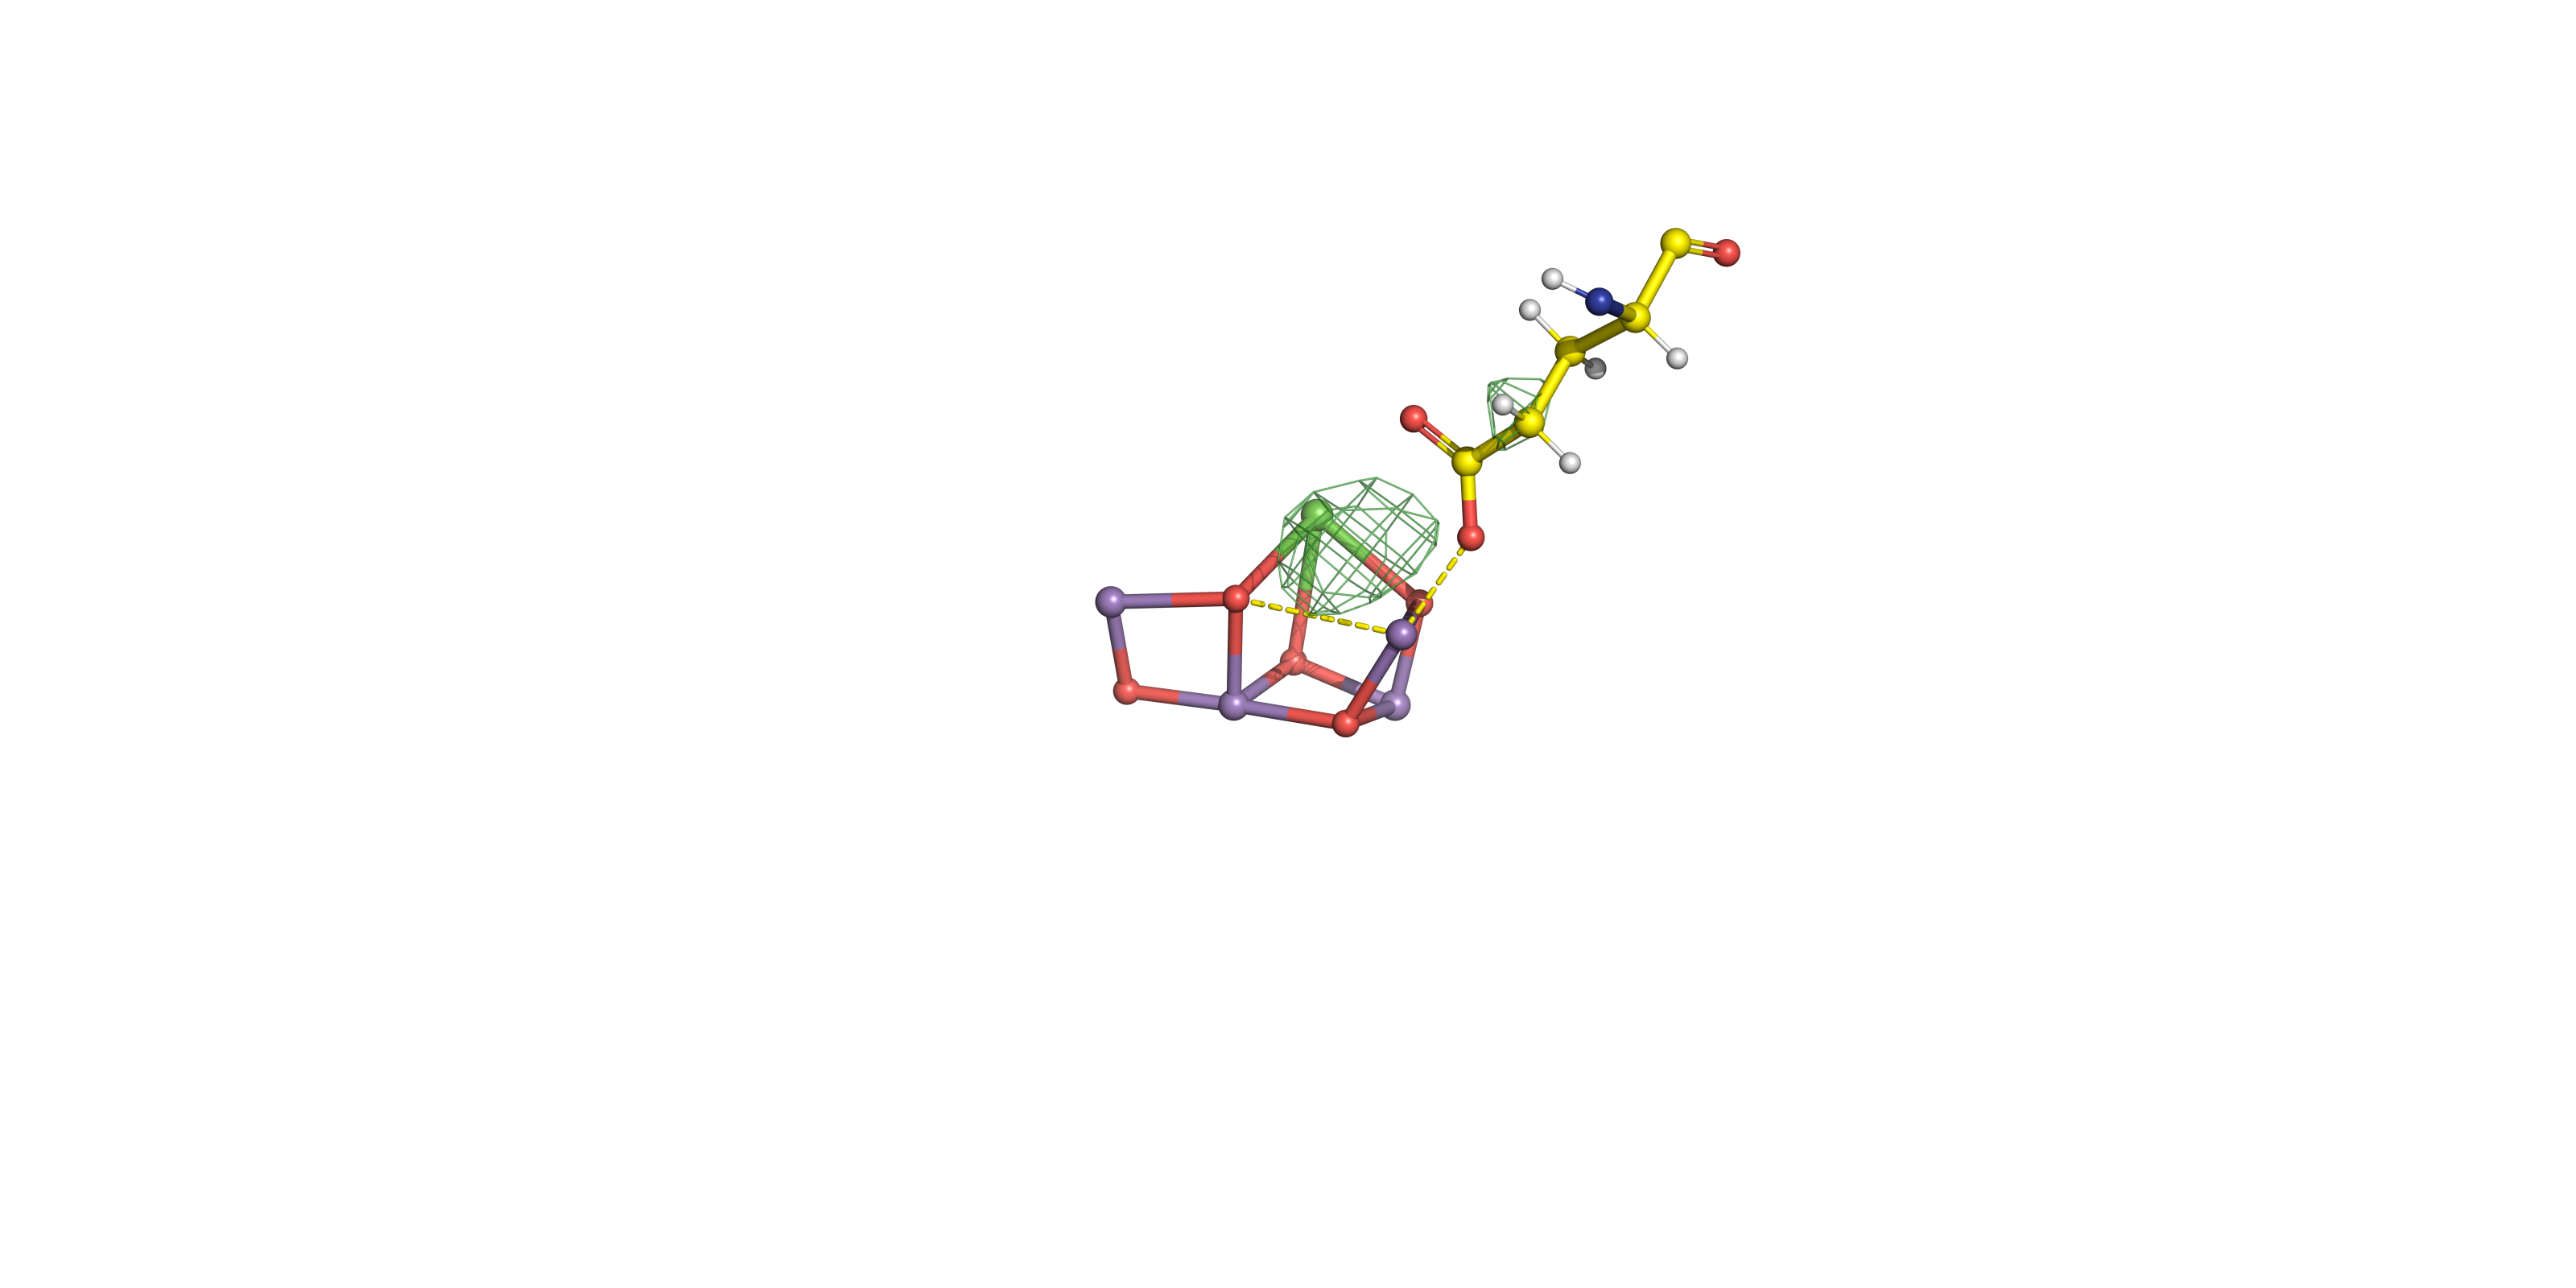

Launching PyMOL. Adjust the view, then quit the window.
 PyMOL(TM) Molecular Graphics System, Version 3.1.0.
 Copyright (c) Schrodinger, LLC.
 All Rights Reserved.
 
    Created by Warren L. DeLano, Ph.D. 
 
    PyMOL is user-supported open-source software.  Although some versions
    are freely available, PyMOL is not in the public domain.
 
    If PyMOL is helpful in your work or study, then please volunteer 
    support for our ongoing efforts to create open and affordable scientific
    software by purchasing a PyMOL Maintenance and/or Support subscription.

    More information can be found at "http://www.pymol.org".
 
    Enter "help" for a list of commands.
    Enter "help <command-name>" for information on a specific command.

 Hit ESC anytime to toggle between text and graphics.

 Detected OpenGL version 2.1. Shaders available.
 Tessellation shaders not available
 Detected GLSL version 1.20.
 OpenGL graphics engine:
  GL_VENDOR:   Apple
  GL_RENDERER: Apple M3
  GL_VERSION:  2

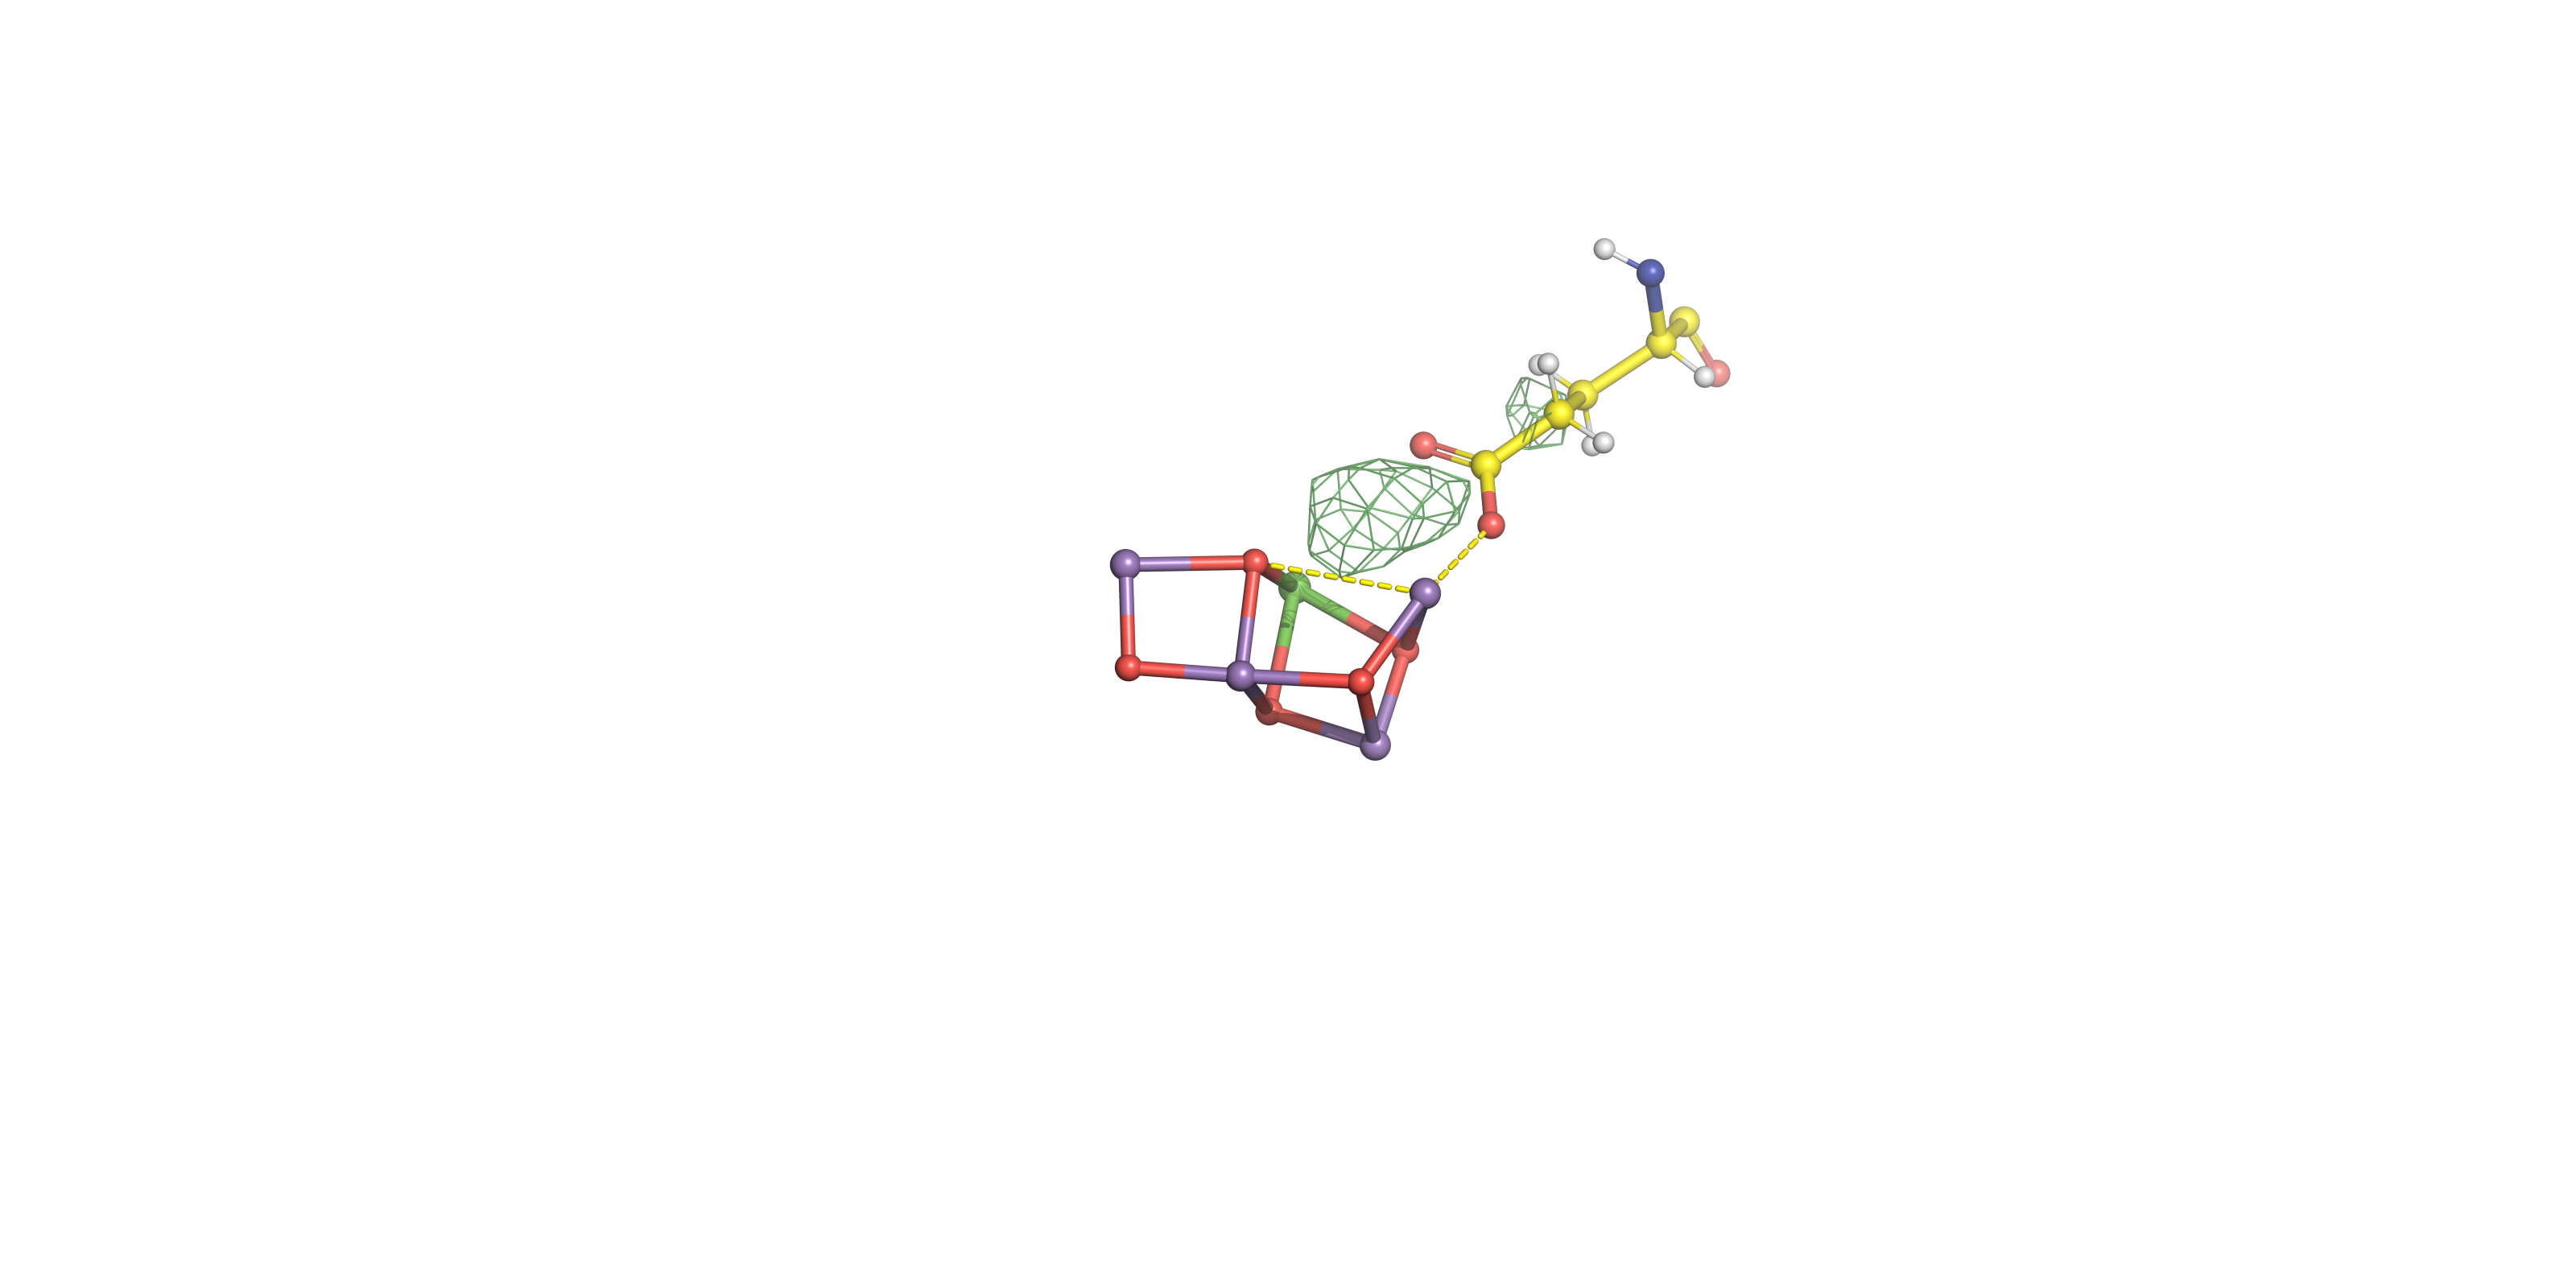

In [38]:
pos_levels = list(SIGMA_POSITIVE if SIGMA_POSITIVE is not None else SIGMA_LEVELS)
neg_levels = list(SIGMA_NEGATIVE if SIGMA_NEGATIVE is not None else SIGMA_LEVELS)
pos_levels = sorted(float(x) for x in pos_levels)
neg_levels = sorted(float(x) for x in neg_levels)

site_sel = f"xyz and chain {SITE_CHAIN} and resi {SITE_RESI}"
png_path = OUTPUT_DIR / f"{LIGHT_ID}_DELFWT_{DARK_ID}_{SITE_LABEL}_{SITE_CHAIN}{SITE_RESI}_diffmap.png"
pml_path = OUTPUT_DIR / f"pymol_{LIGHT_ID}_DELFWT_{DARK_ID}_{SITE_LABEL}.pml"

oec_pairs = [
    ("MN1", "O1"), ("MN1", "O3"),
    ("MN2", "O1"), ("MN2", "O2"), ("MN2", "O3"),
    ("MN3", "O2"), ("MN3", "O3"), ("MN3", "O4"), ("MN3", "O5"),
    ("MN4", "O5"), ("MN4", "O4"),
    ("CA1", "O1"), ("CA1", "O2"), ("CA1", "O5"),
]

stats = ccp4_map_stats(fragment)
print(
    f"Fragment file stats (raw voxels): RMS={stats['rms']:.5f}  "
    f"mean={stats['mean']:.5f}  min={stats['min']:.5f}  max={stats['max']:.5f}  "
    f"grid={int(stats['nx'])}x{int(stats['ny'])}x{int(stats['nz'])}"
)
if CONTOUR_MODE == "sigma":
    # PyMOL normalizes CCP4 maps to mean 0 / RMS 1, so isomesh level n is n-sigma.
    pos_abs = list(pos_levels)
    neg_abs = [-n for n in neg_levels]
    normalize_flag = 1
    print("Contour mode: PyMOL-normalized sigma (isomesh level n = n sigma)")
else:
    pos_abs = list(pos_levels)
    neg_abs = [-n for n in neg_levels]
    normalize_flag = 0
    print("Contour mode: absolute map units (normalize_ccp4_maps off)")

if surface_representation == "mesh":
    contour_cmd = "isomesh"
    surface_transparency = 0.25
elif surface_representation == "solid":
    contour_cmd = "isosurface"
    surface_transparency = 0.45
else:
    raise ValueError(
        "surface_representation must be 'mesh' or 'solid', "
        f"got {surface_representation!r}"
    )
print(f"Surface representation: {surface_representation} ({contour_cmd})")

lines: list[str] = [
    f"set normalize_ccp4_maps, {normalize_flag}",
    f"load {fragment}, DIFF",
    f"load {refined_pdb}, xyz",
    "hide everything",
    "util.cbay xyz",
    f"select site, {site_sel}",
    "show spheres, site",
    "show sticks, site",
    "set sphere_scale, 0.15, xyz",
    "set stick_radius, 0.12, xyz",
]

for extra in EXTRA_RESIDUES:
    lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
    lines += [
        f"select {lab}, xyz and chain {extra['chain']} and resi {extra['resi']}",
        f"show sticks, {lab}",
        f"show spheres, {lab}",
        f"set sphere_scale, 0.15, {lab}",
        f"set stick_radius, 0.12, {lab}",
    ]

if SHOW_OEC_BONDS:
    present = residue_atom_names(refined_pdb, SITE_CHAIN, SITE_RESI)
    for a, b in oec_pairs:
        if a in present and b in present:
            lines.append(f"bond site and name {a}, site and name {b}")

if DRAW_DEFAULT_OEC_DISTANCES:
    present = residue_atom_names(refined_pdb, SITE_CHAIN, SITE_RESI)
    if "MN1" in present and "O5" in present:
        lines.append("distance d_mn1_o5, site and name MN1, site and name O5")
    for extra in EXTRA_RESIDUES:
        extra_atoms = residue_atom_names(refined_pdb, extra["chain"], extra["resi"])
        if "MN1" in present and "OE2" in extra_atoms:
            lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
            lines.append(
                f"distance d_mn1_{lab}_A, site and name MN1, {lab} and alt A and name OE2"
            )
            lines.append(
                f"distance d_mn1_{lab}_B, site and name MN1, {lab} and alt B and name OE2"
            )

lines += [
    "viewport %d,%d" % (PNG_WIDTH, PNG_HEIGHT),
    "bg_color white",
    "space cmyk",
    "set ray_opaque_background, 1",
    "set ray_trace_mode, 0",
    "set ray_trace_fog, 1",
    "set orthoscopic, on",
    "set antialias, 4",
    "set mesh_width, 0.25",
    "set dash_gap, 0.15",
    "set dash_radius, 0.05",
    "hide labels",
    "set auto_zoom, 0",
]

carve_target = "site"
for extra in EXTRA_RESIDUES:
    carve_target += " or " + extra.get("label", f"{extra['chain']}{extra['resi']}")
lines.append(f"select carve_sel, {carve_target}")

for i, (n, level) in enumerate(zip(pos_levels, pos_abs)):
    name = "mappos_" + str(n).replace(".", "p")
    color = POS_COLORS[min(i, len(POS_COLORS) - 1)]
    lines += [
        f"{contour_cmd} {name}, DIFF, {level:.6f}, carve_sel, carve={CARVE_A:.2f}",
        f"color {color}, {name}",
    ]
    print(f"  +{n:g} sigma -> {name} at {level:.5f} ({color})")
for i, (n, level) in enumerate(zip(neg_levels, neg_abs)):
    name = "mapneg_" + str(n).replace(".", "p")
    color = NEG_COLORS[min(i, len(NEG_COLORS) - 1)]
    lines += [
        f"{contour_cmd} {name}, DIFF, {level:.6f}, carve_sel, carve={CARVE_A:.2f}",
        f"color {color}, {name}",
    ]
    print(f"  -{n:g} sigma -> {name} at {level:.5f} ({color})")
if surface_representation == "mesh":
    lines.append("set mesh_width, 0.75, map*")
lines.append(f"set transparency, {surface_transparency:.2f}, map*")

def pymol_camera_commands(view_numbers):
    if not view_numbers:
        return ["orient site", "zoom site, 8"]
    if len(view_numbers) != 18:
        raise ValueError(f"PyMOL view must contain 18 numbers, got {len(view_numbers)}")
    return [
        "python",
        "from pymol import cmd",
        f"cmd.set_view({tuple(float(x) for x in view_numbers)!r})",
        "python end",
    ]


def parse_pymol_view(text):
    if text is None or not str(text).strip():
        return None
    nums = [float(x) for x in re.findall(r"[-+]?(?:\d+\.?\d*|\.\d+)", str(text))]
    if len(nums) != 18:
        raise ValueError(f"PYMOL_VIEW must contain 18 numbers, got {len(nums)}")
    return nums


def format_pymol_view(nums):
    rows = [nums[i:i + 3] for i in range(0, 18, 3)]
    return ",\\\n".join(", ".join(f"{x: .9f}" for x in row) for row in rows)


def run_pymol_headless(script_lines):
    pml_path.write_text("\n".join(script_lines) + "\n")
    print("Wrote", pml_path)
    print("Running PyMOL headless…")
    proc = subprocess.run(
        [str(PYMOL_BIN), "-cq", str(pml_path)],
        cwd=str(OUTPUT_DIR),
        text=True,
        capture_output=True,
    )
    log_path = OUTPUT_DIR / "pymol_render.log"
    log_path.write_text((proc.stdout or "") + (proc.stderr or ""))
    print(proc.stdout or "")
    if proc.returncode == 0 and png_path.is_file():
        return
    # Retry without ray tracing — some macOS builds need a display for ray.
    if RAY_TRACE and any(ln.startswith("png ") and "ray=1" in ln for ln in script_lines):
        print("Ray-traced PNG failed; retrying with ray=0 …")
        fallback = [
            ln.replace("ray=1", "ray=0") if ln.startswith("png ") else ln
            for ln in script_lines
        ]
        pml_path.write_text("\n".join(fallback) + "\n")
        proc = subprocess.run(
            [str(PYMOL_BIN), "-cq", str(pml_path)],
            cwd=str(OUTPUT_DIR),
            text=True,
            capture_output=True,
        )
        log_path.write_text((proc.stdout or "") + (proc.stderr or ""))
        print(proc.stdout or "")
    if proc.returncode != 0 or not png_path.is_file():
        raise RuntimeError(f"PyMOL failed (exit {proc.returncode}). See {log_path}")


def publish_png():
    print("Saved image:", png_path)
    visible = NOTEBOOK_DIR / png_path.name
    if visible.resolve() != png_path.resolve():
        shutil.copy2(png_path, visible)
        print("Copied image:", visible)


scene_lines = list(lines)
ray_flag = 1 if RAY_TRACE else 0
png_cmd = f"png {png_path}, {PNG_WIDTH}, {PNG_HEIGHT}, dpi=200, ray={ray_flag}"
camera = pymol_camera_commands(parse_pymol_view(PYMOL_VIEW))
run_pymol_headless(scene_lines + camera + [png_cmd, "quit"])
publish_png()
sigma_txt = ", ".join(f"+/-{s:g}" for s in pos_levels)
display(Markdown(
    f"**{LIGHT_ID} - {DARK_ID}** difference density around "
    f"`{SITE_LABEL}` {SITE_CHAIN}/{SITE_RESI}, "
    f"contoured at {sigma_txt} sigma "
    f"(positive = stronger in {LIGHT_ID}; negative = stronger in {DARK_ID})."
))
display(Image(filename=str(png_path), width=min(PNG_WIDTH, 1100)))

# INSPECT_IN_PYMOL (configuration cell): open this scene in the PyMOL GUI,
# change the camera, then quit. A moved view is saved and the PNG is redrawn.
if INSPECT_IN_PYMOL:
    view_file = OUTPUT_DIR / "pymol_view.txt"
    view_file.unlink(missing_ok=True)
    inspect_pml = pml_path.with_name(pml_path.stem + "_inspect.pml")
    hook = [
        "python",
        "from pymol import cmd",
        "import threading",
        "import time",
        f"_VIEW_FILE = {str(view_file)!r}",
        "def write_view(echo=1):",
        "    view = cmd.get_view(quiet=1)",
        "    fh = open(_VIEW_FILE, 'w')",
        "    fh.write('\\n'.join('%.9f' % float(x) for x in view))",
        "    fh.close()",
        "    if int(echo):",
        "        print('Wrote PyMOL view to %s' % _VIEW_FILE)",
        "def _watch_view():",
        "    initial = None",
        "    while True:",
        "        try:",
        "            view = [float(x) for x in cmd.get_view(quiet=1)]",
        "            if initial is None:",
        "                initial = view",
        "            elif max(abs(a - b) for a, b in zip(view, initial)) >= 1e-4:",
        "                write_view(0)",
        "        except Exception:",
        "            return",
        "        time.sleep(0.5)",
        "cmd.extend('write_view', write_view)",
        "threading.Thread(target=_watch_view, daemon=True).start()",
        "print('Adjust the view, then quit PyMOL.')",
        "print('If the notebook does not pick up the camera, run write_view before quitting.')",
        "python end",
    ]
    inspect_pml.write_text("\n".join(scene_lines + camera + hook) + "\n")
    print("Launching PyMOL. Adjust the view, then quit the window.")
    proc = subprocess.run(
        [str(PYMOL_BIN), str(inspect_pml)],
        cwd=str(OUTPUT_DIR),
    )
    if proc.returncode not in (0, None):
        print(f"PyMOL exited with status {proc.returncode}.")
    if not view_file.is_file():
        print("View unchanged.")
    else:
        saved = [float(x) for x in view_file.read_text().split()]
        if len(saved) != 18:
            raise RuntimeError(f"Unexpected PyMOL view in {view_file}")
        PYMOL_VIEW = format_pymol_view(saved)
        print("Camera updated for this session. Paste this into the configuration cell to keep it:")
        print("PYMOL_VIEW = '''\\")
        print(PYMOL_VIEW)
        print("'''")
        camera = pymol_camera_commands(saved)
        png_path.unlink(missing_ok=True)
        run_pymol_headless(scene_lines + camera + [png_cmd, "quit"])
        publish_png()
        display(Image(filename=str(png_path), width=min(PNG_WIDTH, 1100)))


## Interpreting the default PSII figure

For the `11yo` omit model against the `6w1v` amplitudes, around the OEC on chain A, positive density is electron density in the 2F observations that the single-conformation model does not include.

- The model drawn in the figure is the refined omit coordinate set (`REFMAC_NCYC` cycles), shown with the difference map from that refinement.
- A positive peak on an atom present in `6w1v` and absent from `11yo` is the expected $mF_o-DF_c$ signal.
- **No requirement** that a strong positive peak sit exactly on O6. Whether the 2F XFEL data support an inserted oxo/water at that position is debated in the literature; this notebook reproduces the *map*, it does not settle that debate.

If the mesh is empty, lower `SIGMA_LEVELS` (try `[3.0]`). If the cage swallows the model, decrease `CARVE_A` or raise the $\sigma$ cutoff. `CONTOUR_MODE = "sigma"` lets PyMOL normalise the CCP4 map so an `isomesh` level is a multiple of the map RMS.

## Adapting the notebook

1. Put the omit-model coordinates, the observed structure factors, and (for the residue scan) the light coordinates in `INPUT_DIR`, or point `DARK_PDB`, `LIGHT_SF`, and `LIGHT_PDB` at them.
2. Set `DARK_ID` / `LIGHT_ID`. Leave `RESOLUTION_SOURCE = "sf"` to take `LOWRES` / `DMIN` from the observed structure-factor MTZ, or set `RESOLUTION_SOURCE = "explicit"` and fill in those two numbers.
3. Run through the residue-scan cell, then set `SITE_CHAIN` / `SITE_RESI` / `EXTRA_RESIDUES`.
4. Set `REFMAC_NCYC`, `SITE_DISTANCE_RESTRAINTS`, `SITE_DISTANCE_SIGMA`, `SITE_ANGLE_RESTRAINTS`, and `SITE_ANGLE_SIGMA` (`SITE_ANGLE_SIGMA` is degrees). Leave `USE_LIBCHECK = False` to pass the distances straight to `refmac5`. Set it to `True` to widen them in a `libcheck` library instead (`LIB_MONOMERS = None` includes the site residue and the other hetero residues). Angle restraints are external in either case. An empty distance or angle list adds no restraints of that kind.
5. Set `PYMOL_VIEW = None` unless you have a camera you want to reuse.
6. Set `RECOMPUTE_MAP = True` the first time; afterwards leave it `False` while you tune $\sigma$ and the view.

To change the camera, set `INSPECT_IN_PYMOL = True` and re-run the render cell. Quit PyMOL when the view looks right; paste the printed matrix into `PYMOL_VIEW` to keep it. You can also open the extended map in Coot with the omit coordinates.
